# LFP Thick-Electrode Fast-Charge Design Study (PyBaMM)

**Goal:** find the electrode design window (cathode **thickness × porosity**) that maximises volumetric
energy density of an LFP/graphite cell while still allowing **2C–3C charging without lithium plating**.

### Notebook map
| Section | What it does |
|---|---|
| 1 | Install & imports |
| 2 | **Explore the DFN model and the Prada2013 cell** (so you know which cell you are simulating) |
| 3 | Study settings (all knobs in one place) |
| 4 | Core functions: parameter builder, simulation, metrics, plotting helpers |
| 5 | **Baseline sweep** (thickness × porosity × C-rate) + analysis plots |
| 6 | **Extension 1** – tortuosity (Bruggeman exponent) sensitivity |
| 7 | **Extension 2** – temperature sensitivity |
| 8 | **Extension 3** – anode design sensitivity (N/P ratio, graphite particle size) |
| 9 | **Extension 4** – charging-time analysis (CC-CV time to 80 % SOC) |
| 10 | Cross-scenario summary, export and download |

**Runtime:** roughly 10–20 min on a free Colab CPU (~400 DFN simulations). Results are cached to CSV files,
so if a section is re-run it reloads instead of recomputing (set `USE_CACHE = False` to force a fresh run).

**Important caveat:** the numbers come from a physics model with an *assumed/modified* parameter set
(Prada2013 with a faster graphite anode). Treat them as **trends**, not as measured cell data.

---
# 1. Setup

## 1.1 Install PyBaMM
If Colab complains about NumPy after the install, use *Runtime → Restart session* and run from the next cell.

In [1]:
!pip install -q pybamm tqdm

## 1.2 Imports and plotting style

In [2]:
import os, itertools, time, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pybamm
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore")
pybamm.set_logging_level("ERROR")

# np.trapz was renamed to np.trapezoid in NumPy 2.x
trapz = getattr(np, "trapezoid", None) or np.trapz

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 8,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

def show(name):
    """Tight layout -> save PNG to ./figures -> display."""
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

print("PyBaMM", pybamm.__version__, "| NumPy", np.__version__)

PyBaMM 26.10.1.1 | NumPy 2.4.6


---
# 2. Understanding the model and the cell we are simulating

## 2.1 What is the DFN model?
PyBaMM's **Doyle–Fuller–Newman (DFN)** model is a 1-D physics-based (pseudo-2D) battery model. It couples:

| Physics | Governing idea | Why it matters here |
|---|---|---|
| Solid-phase diffusion | Li diffuses inside each active-material particle (Fick's law) | Limits fast charge when particles are large (LFP, graphite) |
| Electrolyte transport | Li⁺ migrates & diffuses through the pores (concentrated-solution theory) | **Tortuosity lives here** – effective transport scales as ε^b |
| Charge conduction | Ohm's law in the solid and in the electrolyte | Thick, resistive LFP electrodes lose voltage |
| Interfacial kinetics | Butler–Volmer reaction at every particle surface | Sets the overpotential at the anode (plating risk) |

**Tortuosity in the model:** effective electrolyte diffusivity and conductivity are multiplied by ε^b, where ε is the
porosity and *b* is the **Bruggeman exponent** (default 1.5). Lower porosity or larger *b* → slower ion transport.

## 2.2 Inspect the DFN model object (options and variables)

In [3]:
model = pybamm.lithium_ion.DFN()

print("DFN options (the physics switches):")
for k, v in model.options.items():
    print(f"  {k:45s} {v}")

print(f"\nNumber of output variables available: {len(model.variables)}")
print("\nSubmodels used (first 15):")
try:
    for name in list(model.submodels.keys())[:15]:
        print("  -", name)
except Exception:
    pass

DFN options (the physics switches):
  calculate discharge energy                    false
  calculate heat source for isothermal models   false
  cell geometry                                 arbitrary
  contact resistance                            false
  convection                                    none
  current collector                             uniform
  diffusivity                                   single
  dimensionality                                0
  electrolyte conductivity                      default
  exchange-current density                      single
  heat of mixing                                false
  hydrolysis                                    false
  intercalation kinetics                        symmetric Butler-Volmer
  interface utilisation                         full
  lithium plating                               none
  lithium plating porosity change               false
  loss of active material                       none
  number of MSMR reactions

Variables you can search for. Run `model.variables.search("keyword")` to find any output you want to plot.

In [4]:
for kw in ["Electrolyte concentration", "surface potential difference", "Terminal voltage", "Discharge capacity"]:
    print(f"\n--- variables matching '{kw}' ---")
    model.variables.search(kw)


--- variables matching 'Electrolyte concentration' ---
Results for 'Electrolyte concentration': ['Electrolyte concentration concatenation [mol.m-3]', 'Negative electrolyte concentration [mol.m-3]', 'X-averaged negative electrolyte concentration [mol.m-3]', 'Separator electrolyte concentration [mol.m-3]', 'X-averaged separator electrolyte concentration [mol.m-3]', 'Positive electrolyte concentration [mol.m-3]', 'X-averaged positive electrolyte concentration [mol.m-3]', 'Negative electrolyte concentration [Molar]', 'X-averaged negative electrolyte concentration [Molar]', 'Separator electrolyte concentration [Molar]', 'X-averaged separator electrolyte concentration [Molar]', 'Positive electrolyte concentration [Molar]', 'X-averaged positive electrolyte concentration [Molar]', 'Electrolyte concentration [mol.m-3]', 'X-averaged electrolyte concentration [mol.m-3]', 'Electrolyte concentration [Molar]', 'X-averaged electrolyte concentration [Molar]']

--- variables matching 'surface potentia

## 2.3 The Prada2013 parameter set (LFP / graphite)
`Prada2013` is PyBaMM's built-in **LFP cathode / graphite anode** set (A123-type 26650 cell chemistry,
Prada et al., J. Electrochem. Soc. 2013). Below we group every scalar parameter by component.

In [5]:
pv0 = pybamm.ParameterValues("Prada2013")

def categorize(key):
    k = key.lower()
    if k.startswith("negative electrode"): return "1 Negative electrode (graphite)"
    if k.startswith("positive electrode"): return "2 Positive electrode (LFP)"
    if k.startswith("negative particle") or "negative" in k: return "1 Negative electrode (graphite)"
    if k.startswith("positive particle") or "positive" in k: return "2 Positive electrode (LFP)"
    if "separator" in k: return "3 Separator"
    if "electrolyte" in k or "cation" in k or "transference" in k: return "4 Electrolyte"
    if "temperature" in k or "thermal" in k or "heat" in k: return "6 Thermal / temperature"
    return "5 Cell / general"

scalar_rows, function_rows = [], []
for k in sorted(pv0.keys()):
    v = pv0[k]
    if isinstance(v, (int, float, np.integer, np.floating)):
        unit = k[k.rfind("[")+1:k.rfind("]")] if "[" in k else "-"
        scalar_rows.append(dict(group=categorize(k), parameter=k, value=float(v), unit=unit))
    else:
        function_rows.append(k)

param_table = pd.DataFrame(scalar_rows).sort_values(["group", "parameter"]).reset_index(drop=True)
print(f"{len(param_table)} scalar parameters, {len(function_rows)} function-valued parameters")
for g, sub in param_table.groupby("group"):
    print(f"\n=== {g[2:]} ===")
    display(sub[["parameter", "value", "unit"]].reset_index(drop=True))

print("\nFunction-valued parameters (OCPs, kinetics, temperature laws, ...):")
for f in function_rows:
    print("  -", f)

47 scalar parameters, 6 function-valued parameters

=== Negative electrode (graphite) ===


,parameter,value,unit
0,Initial concentration in negative electrode [m...,2.474955e+04,mol.m-3
1,Maximum concentration in negative electrode [m...,3.055500e+04,mol.m-3
2,Negative electrode Bruggeman coefficient (elec...,1.500000e+00,-
3,Negative electrode Bruggeman coefficient (elec...,1.500000e+00,-
4,Negative electrode OCP entropic change [V.K-1],0.000000e+00,V.K-1
5,Negative electrode active material volume frac...,5.800000e-01,-
6,Negative electrode charge transfer coefficient,5.000000e-01,-
7,Negative electrode conductivity [S.m-1],2.150000e+02,S.m-1
8,Negative electrode double-layer capacity [F.m-2],2.000000e-01,F.m-2
9,Negative electrode porosity,3.600000e-01,-



=== Positive electrode (LFP) ===


,parameter,value,unit
0,Initial concentration in positive electrode [m...,8.666280e+01,mol.m-3
1,Maximum concentration in positive electrode [m...,2.280600e+04,mol.m-3
2,Positive electrode Bruggeman coefficient (elec...,1.500000e+00,-
3,Positive electrode Bruggeman coefficient (elec...,1.500000e+00,-
4,Positive electrode OCP entropic change [V.K-1],0.000000e+00,V.K-1
5,Positive electrode active material volume frac...,3.740000e-01,-
6,Positive electrode charge transfer coefficient,5.000000e-01,-
7,Positive electrode conductivity [S.m-1],3.379507e-01,S.m-1
8,Positive electrode double-layer capacity [F.m-2],2.000000e-01,F.m-2
9,Positive electrode porosity,4.260000e-01,-



=== Separator ===


,parameter,value,unit
0,Separator Bruggeman coefficient (electrolyte),1.500000,-
1,Separator porosity,0.450000,-
2,Separator thickness [m],0.000025,m


... (3 outputs left out)

,parameter,value,unit
0,Contact resistance [Ohm],0.0,Ohm
1,Current function [A],2.3,A
2,Electrode height [m],0.6,m
3,Electrode width [m],0.3,m
4,Lower voltage cut-off [V],2.0,V
5,Nominal cell capacity [A.h],2.3,A.h
6,Number of cells connected in series to make a ...,1.0,-
7,Number of electrodes connected in parallel to ...,1.0,-
8,Open-circuit voltage at 0% SOC [V],2.0,V
9,Open-circuit voltage at 100% SOC [V],3.6,V



=== Thermal / temperature ===


,parameter,value,unit
0,Ambient temperature [K],298.0,K
1,Initial temperature [K],298.0,K
2,Reference temperature [K],298.0,K



Function-valued parameters (OCPs, kinetics, temperature laws, ...):
  - Electrolyte conductivity [S.m-1]
  - Negative electrode OCP [V]
  - Negative electrode exchange-current density [A.m-2]
  - Positive electrode OCP [V]
  - Positive electrode exchange-current density [A.m-2]
  - citations


### Key parameters we will vary or depend on (plain-English meaning)

In [6]:
glossary = {
    "Positive electrode thickness [m]":  "LFP coating thickness  -> SWEPT in this study",
    "Positive electrode porosity":        "Pore volume fraction of LFP coating (set by calendering) -> SWEPT",
    "Positive electrode active material volume fraction": "LFP volume share of the electrode (we link it to porosity)",
    "Positive particle radius [m]":       "LFP particle size (tiny, nano-scale -> fast solid diffusion)",
    "Positive electrode conductivity [S.m-1]": "Electronic conductivity of the LFP+carbon network (low!)",
    "Positive electrode Bruggeman coefficient (electrolyte)": "Tortuosity exponent b in eps^b for the cathode -> SENSITIVITY (Sec. 6)",
    "Maximum concentration in positive electrode [mol.m-3]": "Li storage capacity of LFP",
    "Negative electrode thickness [m]":   "Graphite thickness (we re-size it to keep N/P fixed)",
    "Negative particle radius [m]":       "Graphite particle size -> SENSITIVITY (Sec. 8)",
    "Negative electrode porosity":        "Pore fraction of the anode",
    "Maximum concentration in negative electrode [mol.m-3]": "Li storage capacity of graphite",
    "Separator thickness [m]":            "Separator thickness",
    "Initial concentration in electrolyte [mol.m-3]": "Electrolyte salt concentration (1.2 M)",
    "Lower voltage cut-off [V]":          "Default discharge cut-off in the parameter set",
    "Upper voltage cut-off [V]":          "Default charge cut-off in the parameter set",
    "Electrode height [m]": "Electrode height (sets area)", "Electrode width [m]": "Electrode width (sets area)",
    "Nominal cell capacity [A.h]":        "Capacity used to convert C-rate -> amps",
    "Ambient temperature [K]":            "Temperature -> SENSITIVITY (Sec. 7)",
}
rows = [dict(parameter=k, value=pv0[k] if k in pv0.keys() else None, meaning=v)
        for k, v in glossary.items() if k in pv0.keys()]
display(pd.DataFrame(rows))

,parameter,value,meaning
0,Positive electrode thickness [m],8.000000e-05,LFP coating thickness -> SWEPT in this study
1,Positive electrode porosity,4.260000e-01,Pore volume fraction of LFP coating (set by ca...
2,Positive electrode active material volume frac...,3.740000e-01,LFP volume share of the electrode (we link it ...
3,Positive particle radius [m],5.000000e-08,"LFP particle size (tiny, nano-scale -> fast so..."
4,Positive electrode conductivity [S.m-1],3.379507e-01,Electronic conductivity of the LFP+carbon netw...
5,Positive electrode Bruggeman coefficient (elec...,1.500000e+00,Tortuosity exponent b in eps^b for the cathode...
6,Maximum concentration in positive electrode [m...,2.280600e+04,Li storage capacity of LFP
7,Negative electrode thickness [m],3.400000e-05,Graphite thickness (we re-size it to keep N/P ...
8,Negative particle radius [m],5.000000e-06,Graphite particle size -> SENSITIVITY (Sec. 8)
9,Negative electrode porosity,3.600000e-01,Pore fraction of the anode


## 2.4 Derived properties of the *unmodified* Prada2013 cell
These are quantities that the parameter set implies but does not list directly.

In [7]:
F = 96485.0
H, W = pv0["Electrode height [m]"], pv0["Electrode width [m]"]
area = H * W
Lp, Ln = pv0["Positive electrode thickness [m]"], pv0["Negative electrode thickness [m]"]
Ls = pv0["Separator thickness [m]"]
amp, amn = pv0["Positive electrode active material volume fraction"], pv0["Negative electrode active material volume fraction"]
cmp_, cmn = pv0["Maximum concentration in positive electrode [mol.m-3]"], pv0["Maximum concentration in negative electrode [mol.m-3]"]

Qp_areal = Lp * amp * cmp_ * F / 3600           # A.h per m2 of electrode
Qn_areal = Ln * amn * cmn * F / 3600

derived = {
    "Electrode area [cm2]": area * 1e4,
    "Nominal capacity from table [A.h]": pv0["Nominal cell capacity [A.h]"],
    "Cathode areal capacity (c_max basis) [mAh/cm2]": Qp_areal / 10,
    "Anode areal capacity (c_max basis) [mAh/cm2]": Qn_areal / 10,
    "N/P ratio (c_max basis)": Qn_areal / Qp_areal,
    "Cathode capacity over full area [A.h]": Qp_areal * area,
    "Cathode solid fraction (1 - porosity)": 1 - pv0["Positive electrode porosity"],
    "Cathode active fraction of electrode volume": amp,
    "Active share of cathode solids": amp / (1 - pv0["Positive electrode porosity"]),
    "Positive / negative particle radius [um]": f'{pv0["Positive particle radius [m]"]*1e6:.3f} / {pv0["Negative particle radius [m]"]*1e6:.2f}',
}
# implied LFP mAh/g properly: (c_max mol/m3 * F / 3600 = Ah/m3) -> /1e6 = Ah/cm3 -> *1e3 = mAh/cm3 -> /3.6 g/cm3
derived["Implied LFP capacity [mAh/g] (assuming 3.6 g/cm3)"] = cmp_ * F / 3600 / 1e6 * 1e3 / 3.6
display(pd.Series(derived, name="value").to_frame())

,value
Electrode area [cm2],1800.0
Nominal capacity from table [A.h],2.3
Cathode areal capacity (c_max basis) [mAh/cm2],1.828808
Anode areal capacity (c_max basis) [mAh/cm2],1.614903
N/P ratio (c_max basis),0.883036
Cathode capacity over full area [A.h],3.291854
Cathode solid fraction (1 - porosity),0.574
Cathode active fraction of electrode volume,0.374
Active share of cathode solids,0.651568
Positive / negative particle radius [um],0.050 / 5.00


## 2.5 What does the baseline cell look like electrically?
We run the *unmodified* Prada2013 cell at several discharge rates, then look at the electrode potentials.
**Notice the flat voltage plateau (~3.3 V)** – the signature of LFP. It makes the voltage insensitive to SOC,
which is why overpotentials (transport limits) dominate when you fast-charge.

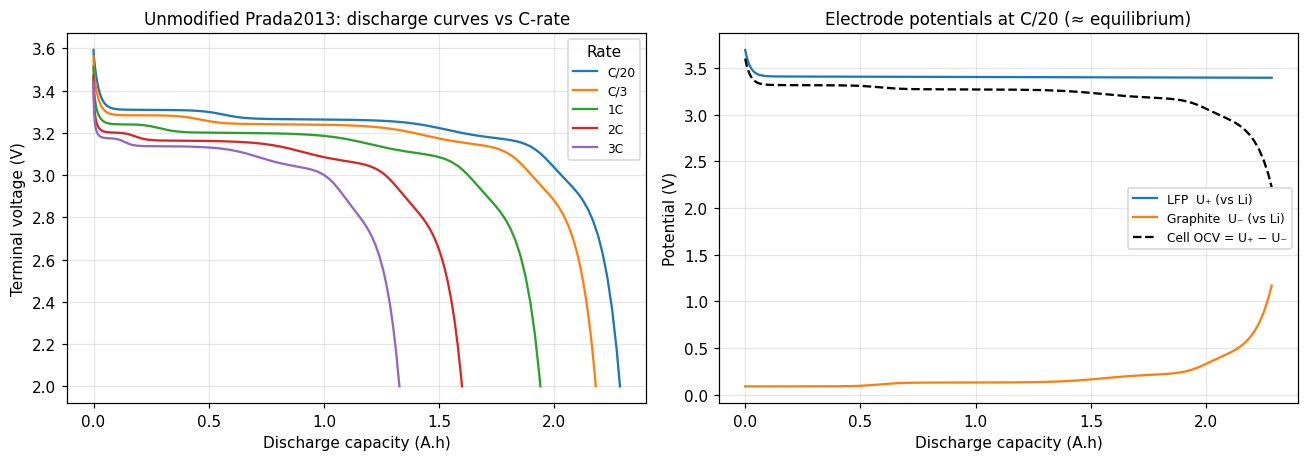

In [8]:
base_model = pybamm.lithium_ion.DFN()
rates = ["C/20", "C/3", "1C", "2C", "3C"]
sols = {}
for r in rates:
    exp = pybamm.Experiment([f"Discharge at {r} until 2.0 V"])
    sim = pybamm.Simulation(base_model, parameter_values=pv0, experiment=exp)
    sols[r] = sim.solve()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for r, s in sols.items():
    axes[0].plot(s["Discharge capacity [A.h]"].entries, s["Voltage [V]"].entries, label=r)
axes[0].set(xlabel="Discharge capacity (A.h)", ylabel="Terminal voltage (V)",
            title="Unmodified Prada2013: discharge curves vs C-rate")
axes[0].legend(title="Rate")

s = sols["C/20"]
q = s["Discharge capacity [A.h]"].entries
Up = s["Positive electrode bulk open-circuit potential [V]"].entries
Un = s["Negative electrode bulk open-circuit potential [V]"].entries
axes[1].plot(q, Up, label="LFP  U₊ (vs Li)")
axes[1].plot(q, Un, label="Graphite  U₋ (vs Li)")
axes[1].plot(q, Up - Un, "k--", label="Cell OCV = U₊ − U₋")
axes[1].set(xlabel="Discharge capacity (A.h)", ylabel="Potential (V)",
            title="Electrode potentials at C/20 (≈ equilibrium)")
axes[1].legend()
show("sec2_baseline_cell")

**How to read this:** the graphite potential **U₋** sits just above 0 V (vs Li/Li⁺) for most of the charge.
During fast charge the anode is pushed *down* by overpotential. If its surface potential reaches **0 V**,
lithium metal can deposit instead of intercalating — that is **lithium plating**, the failure mode we screen for.

---
# 3. Study settings
All design assumptions live here. Swept variables are in the grids; sensitivity studies override entries in `BASE_CFG`.

In [9]:
# ---- Fixed design assumptions (not swept) ----
FIXED = dict(
    AM_FRAC_OF_SOLIDS = 0.90,   # LFP share of cathode solids (rest = carbon + binder). Links porosity -> active fraction
    AM_FRAC_N         = 0.90,   # graphite share of anode solids
    POROSITY_N        = 0.35,   # anode porosity
    USABLE_N          = 0.90,   # fraction of graphite capacity actually cycled (used for N/P sizing)
    L_SEP             = 20e-6,  # separator thickness [m]
    L_CC_P            = 12e-6,  # Al foil [m]
    L_CC_N            = 8e-6,   # Cu foil [m]
    V_MAX             = 3.65,   # charge voltage limit [V]
    V_MIN             = 2.5,    # discharge cut-off [V]
    SOC_TARGET        = 0.80,   # fast-charge target: 0 -> 80 % of discharged capacity
    T80_TOLERANCE     = 1.25,   # CC-CV counts as "fast" if t80 <= 1.25 x ideal CC time
    CV_CUTOFF_C       = 1/20,   # end the CV hold at C/20
)

# ---- Baseline configuration (overridden in sensitivity sections) ----
BASE_CFG = dict(
    bruggeman     = 1.5,        # tortuosity exponent b (try 2.0-2.5 in Sec. 6)
    T_K           = 298.15,     # temperature [K]
    np_ratio      = 1.20,       # anode/cathode areal capacity ratio
    anode_r_scale = 0.25,       # graphite particle radius multiplier (1.0 = stock Prada2013 graphite)
)

# ---- Sweep grids ----
THICKNESSES_UM = [40, 60, 80, 100, 120, 140, 160]       # full baseline grid
POROSITIES     = [0.25, 0.30, 0.35, 0.40, 0.45]
C_RATES        = [2.0, 3.0]

GRID_T = [40, 60, 80, 100, 120, 140]                    # coarser grid for sensitivity studies (subset of full grid)
GRID_E = [0.25, 0.35, 0.45]

USE_CACHE = True

---
# 4. Core functions

## 4.1 Parameter builder
Turns one design point (cathode thickness, porosity, configuration) into a complete PyBaMM parameter set:
* **Calendering → active fraction:** `active fraction = (1 − porosity) × AM_FRAC_OF_SOLIDS`
* **Anode sizing:** graphite thickness chosen so the anode capacity = `np_ratio` × cathode capacity
* **Tortuosity:** Bruggeman exponent applied to the cathode
* **Volume for energy density:** cathode + anode + separator + half of each foil

In [10]:
def build_parameters(L_p, eps_p, cfg):
    pv = pybamm.ParameterValues("Prada2013")
    am_p = (1 - eps_p) * FIXED["AM_FRAC_OF_SOLIDS"]
    am_n = (1 - FIXED["POROSITY_N"]) * FIXED["AM_FRAC_N"]

    F = 96485.0
    cmax_p = pv["Maximum concentration in positive electrode [mol.m-3]"]
    cmax_n = pv["Maximum concentration in negative electrode [mol.m-3]"]
    Q_p = L_p * am_p * cmax_p * F / 3600                                          # A.h/m2 (cathode)
    L_n = cfg["np_ratio"] * Q_p / (am_n * cmax_n * FIXED["USABLE_N"] * F / 3600)  # anode thickness for target N/P

    pv.update({
        "Positive electrode thickness [m]": L_p,
        "Positive electrode porosity": eps_p,
        "Positive electrode active material volume fraction": am_p,
        "Positive electrode Bruggeman coefficient (electrolyte)": cfg["bruggeman"],
        "Positive electrode Bruggeman coefficient (electrode)": cfg["bruggeman"],
        "Negative electrode thickness [m]": L_n,
        "Negative electrode porosity": FIXED["POROSITY_N"],
        "Negative electrode active material volume fraction": am_n,
        "Separator thickness [m]": FIXED["L_SEP"],
        "Negative particle radius [m]": pv["Negative particle radius [m]"] * cfg["anode_r_scale"],
        "Ambient temperature [K]": cfg["T_K"],
        "Initial temperature [K]": cfg["T_K"],
    }, check_already_exists=False)

    area = pv["Electrode height [m]"] * pv["Electrode width [m]"]
    cap_Ah = Q_p * area
    pv.update({"Nominal cell capacity [A.h]": cap_Ah}, check_already_exists=False)
    vol_m3 = area * (L_p + L_n + FIXED["L_SEP"] + 0.5 * (FIXED["L_CC_P"] + FIXED["L_CC_N"]))
    return pv, cap_Ah, vol_m3, L_n

## 4.2 One simulation = one design at one C-rate
Protocol per design: **C/3 discharge → 5 min rest → CC charge at xC to 3.65 V → CV hold at 3.65 V until C/20**.

Metrics recorded:
* `vol_energy_Wh_per_L` – energy of the C/3 discharge ÷ repeat-unit volume
* `cc_charge_fraction` – capacity delivered in the **CC** phase ÷ discharge capacity
* `min_anode_potential_V` – minimum anode surface potential vs Li/Li⁺ from start of charge **to 80 % SOC** (plating if < 0 V)
* `t80_min` – time to reach 80 % SOC with CC-CV (NaN if never reached);  `t80_ideal_min` – time if CC all the way
* `feasible` – plating-free **and** ≥ 80 % delivered in CC (strict fast-charge definition)
* `feasible_ccv` – plating-free **and** `t80 ≤ T80_TOLERANCE × ideal` (relaxed, CC-CV definition)

In [11]:
def anode_potential(step):
    """Anode surface potential vs Li/Li+ at the separator interface [V]; < 0 V => plating is thermodynamically possible."""
    for name in ["Negative electrode surface potential difference at separator interface [V]",
                 "Negative electrode surface potential difference [V]"]:
        try:
            return step[name].entries
        except KeyError:
            continue
    raise KeyError("Anode surface potential variable not found; use model.variables.search('potential').")


def run_design(L_um, eps_p, crate, cfg=None, return_sol=False):
    cfg = {**BASE_CFG, **(cfg or {})}
    pv, cap, vol, L_n = build_parameters(L_um * 1e-6, eps_p, cfg)

    I_dis, I_chg = cap / 3.0, cap * crate
    exp = pybamm.Experiment([(
        f"Discharge at {I_dis:.6f} A until {FIXED['V_MIN']} V",
        "Rest for 5 minutes",
        f"Charge at {I_chg:.6f} A until {FIXED['V_MAX']} V",
        f"Hold at {FIXED['V_MAX']} V for 2 hours or until {cap * FIXED['CV_CUTOFF_C']:.6f} A",
    )])
    sim = pybamm.Simulation(pybamm.lithium_ion.DFN(options={"thermal": "isothermal"}),
                            parameter_values=pv, experiment=exp)
    sol = sim.solve()
    steps = sol.cycles[0].steps
    dis, cc = steps[0], steps[2]
    cv = steps[3] if len(steps) > 3 else None

    # --- energy from the C/3 discharge ---
    t, V, I = dis["Time [s]"].entries, dis["Voltage [V]"].entries, dis["Current [A]"].entries
    E_Wh, Q_dis = trapz(V * I, t) / 3600, trapz(I, t) / 3600

    # --- charge arrays (CC then CV), referenced to the start of the CC step ---
    t_cc, q_cc, e_cc = cc["Time [s]"].entries, cc["Discharge capacity [A.h]"].entries, anode_potential(cc)
    t_all, q_all, e_all = t_cc, q_cc, e_cc
    if cv is not None:
        t_all = np.r_[t_cc, cv["Time [s]"].entries]
        q_all = np.r_[q_cc, cv["Discharge capacity [A.h]"].entries]
        e_all = np.r_[e_cc, anode_potential(cv)]
    q_abs = np.abs(q_all - q_cc[0])
    q_cc_end = abs(q_cc[-1] - q_cc[0])

    target_q = FIXED["SOC_TARGET"] * Q_dis
    if q_abs[-1] >= target_q:
        idx = min(int(np.searchsorted(q_abs, target_q)), len(q_abs) - 1)
        t80_min = (t_all[idx] - t_cc[0]) / 60
    else:                                        # 80 % never reached, even with CV
        idx, t80_min = len(q_abs) - 1, np.nan
    eta_min = float(np.min(e_all[: idx + 1]))
    t80_ideal = target_q / I_chg * 60            # minutes if CC were possible all the way to 80 %

    cc_fraction = q_cc_end / Q_dis
    plating_free = eta_min > 0.0
    res = dict(
        thickness_um=L_um, porosity=eps_p, c_rate=crate,
        bruggeman=cfg["bruggeman"], T_C=cfg["T_K"] - 273.15, np_ratio=cfg["np_ratio"], anode_r_scale=cfg["anode_r_scale"],
        anode_thickness_um=L_n * 1e6, cap_Ah=cap, energy_Wh=E_Wh,
        vol_energy_Wh_per_L=E_Wh / (vol * 1e3),
        cc_charge_fraction=cc_fraction, t80_min=t80_min, t80_ideal_min=t80_ideal,
        t80_penalty=t80_min / t80_ideal if np.isfinite(t80_min) else np.nan,
        min_anode_potential_V=eta_min, plating_free=plating_free,
        meets_charge_target=cc_fraction >= FIXED["SOC_TARGET"],
        feasible=bool(plating_free and cc_fraction >= FIXED["SOC_TARGET"]),
        feasible_ccv=bool(plating_free and np.isfinite(t80_min) and t80_min <= FIXED["T80_TOLERANCE"] * t80_ideal),
        failed=False,
    )
    return (res, sol) if return_sol else res

## 4.3 Sweep runner (with progress bar and CSV caching)

In [12]:
def run_sweep(thicknesses, porosities, c_rates, cfg=None, label="run"):
    path = f"results/{label}.csv"
    if USE_CACHE and os.path.exists(path):
        print(f"[cache] loaded {path}")
        return pd.read_csv(path)
    cfg_full = {**BASE_CFG, **(cfg or {})}
    rows = []
    combos = list(itertools.product(thicknesses, porosities, c_rates))
    for L, eps, c in tqdm(combos, desc=label):
        try:
            rows.append(run_design(L, eps, c, cfg))
        except Exception as e:           # solver failure at extreme designs -> mark infeasible
            rows.append(dict(thickness_um=L, porosity=eps, c_rate=c, bruggeman=cfg_full["bruggeman"],
                             T_C=cfg_full["T_K"] - 273.15, np_ratio=cfg_full["np_ratio"],
                             anode_r_scale=cfg_full["anode_r_scale"], plating_free=False,
                             meets_charge_target=False, feasible=False, feasible_ccv=False, failed=True))
    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    n_fail = int(df.failed.sum())
    print(f"{label}: {len(df)} runs, {n_fail} failed")
    return df

def coarse(df):
    """Subset of a full-grid result on the coarse sensitivity grid."""
    return df[df.thickness_um.isin(GRID_T) & df.porosity.isin(GRID_E)].copy()

## 4.4 Analysis helpers

In [13]:
def max_feasible_thickness(d, feas="feasible"):
    """Largest thickness for which this design AND every thinner one passes."""
    best = np.nan
    for _, r in d.sort_values("thickness_um").iterrows():
        if r[feas]: best = r.thickness_um
        else: break
    return best

def best_at_rate(df, c, feas="feasible"):
    """Highest-energy feasible design at one C-rate."""
    d = df[(df.c_rate == c) & (df[feas] == True)]
    if d.empty: return dict(energy=np.nan, thickness=np.nan, porosity=np.nan)
    r = d.loc[d.vol_energy_Wh_per_L.idxmax()]
    return dict(energy=r.vol_energy_Wh_per_L, thickness=r.thickness_um, porosity=r.porosity)

def best_design_all_rates(df, feas="feasible"):
    """Highest-energy design that passes at ALL C-rates simultaneously."""
    ok = df[df[feas] == True]
    good = ok.groupby(["thickness_um", "porosity"]).filter(lambda g: g.c_rate.nunique() == df.c_rate.nunique())
    if good.empty: return None
    g = good.groupby(["thickness_um", "porosity"]).vol_energy_Wh_per_L.first().sort_values(ascending=False)
    return g

def pivot(d, col):
    return d.pivot_table(index="porosity", columns="thickness_um", values=col, aggfunc="mean")

def plot_window(df, feas="feasible", title="", fname=None, overlay=None):
    """Energy contours + red line = feasibility boundary. `overlay` = second feasibility column drawn in blue."""
    rates = sorted(df.c_rate.unique())
    fig, axes = plt.subplots(1, len(rates), figsize=(6.5 * len(rates), 4.8), squeeze=False)
    for ax, c in zip(axes[0], rates):
        d = df[df.c_rate == c].copy()
        Z = pivot(d, "vol_energy_Wh_per_L")
        X, Y = np.meshgrid(Z.columns.values, Z.index.values)
        cs = ax.contourf(X, Y, Z.values, levels=15, cmap="viridis")
        fig.colorbar(cs, ax=ax, label="Volumetric energy density (Wh/L)")
        for col, color, lw, ls in [(feas, "red", 3.5, "-")] + ([(overlay, "deepskyblue", 1.8, "--")] if overlay else []):
            d["_f"] = d[col].astype(float)
            Fz = pivot(d, "_f")
            if Fz.values.min() < 0.5 < Fz.values.max():
                ax.contour(X, Y, Fz.values, levels=[0.5], colors=color, linewidths=lw, linestyles=ls)
                if col == feas:
                    ax.contourf(X, Y, Fz.values, levels=[-0.1, 0.5], colors="none", hatches=["//"])
        d["_ok"] = d[feas].astype(bool)
        ax.scatter(d.thickness_um, d.porosity, c=np.where(d._ok, "white", "black"), s=18, edgecolors="k", linewidths=0.5)
        ax.set_title(f"{title}{c:.0f}C\nred = feasible edge (hatched = infeasible)" +
                     ("; blue dashed = 2nd criterion" if overlay else ""), fontsize=9)
        ax.set_xlabel("LFP cathode thickness (µm)"); ax.set_ylabel("Cathode porosity (–)")
    if fname: show(fname)
    else: plt.tight_layout(); plt.show()

def family_report(fam, fam_name, fmt, eps_ref=0.35, tag="fam"):
    """Standard analysis for a family of scenarios {value: df}: limit curves, failure-mode curves, best-energy bars, table."""
    rates = sorted(next(iter(fam.values())).c_rate.unique())
    colors = plt.cm.plasma(np.linspace(0.05, 0.85, len(fam)))

    # (a) maximum feasible thickness vs porosity
    fig, axes = plt.subplots(1, len(rates), figsize=(6 * len(rates), 4.2), sharey=True, squeeze=False)
    for ax, c in zip(axes[0], rates):
        for col, (val, df) in zip(colors, fam.items()):
            eps_list = sorted(df.porosity.unique())
            lim = [max_feasible_thickness(df[(df.c_rate == c) & (df.porosity == e)]) for e in eps_list]
            ax.plot(eps_list, np.nan_to_num(lim, nan=0), "o-", color=col, label=fmt(val))
        ax.set(title=f"{c:.0f}C: max feasible cathode thickness", xlabel="Cathode porosity (–)")
    axes[0][0].set_ylabel("Max feasible thickness (µm)  [0 = none]"); axes[0][0].legend(title=fam_name)
    show(f"{tag}_limit_curves")

    # (b) failure modes vs thickness at a reference porosity
    fig, axes = plt.subplots(2, len(rates), figsize=(6 * len(rates), 7), sharex=True, squeeze=False)
    for j, c in enumerate(rates):
        for col, (val, df) in zip(colors, fam.items()):
            d = df[(df.c_rate == c) & (df.porosity == eps_ref)].sort_values("thickness_um")
            axes[0][j].plot(d.thickness_um, d.cc_charge_fraction, "o-", color=col, label=fmt(val))
            axes[1][j].plot(d.thickness_um, d.min_anode_potential_V * 1e3, "o-", color=col, label=fmt(val))
        axes[0][j].axhline(FIXED["SOC_TARGET"], color="k", ls="--", lw=1)
        axes[1][j].axhline(0, color="k", ls="--", lw=1)
        axes[0][j].set(title=f"{c:.0f}C, porosity {eps_ref}: CC charge fraction (need ≥ {FIXED['SOC_TARGET']:.1f})")
        axes[1][j].set(title="Min anode potential to 80 % SOC (need > 0 mV)", xlabel="Cathode thickness (µm)")
    axes[0][0].set_ylabel("CC fraction (–)"); axes[1][0].set_ylabel("Min anode potential (mV vs Li/Li⁺)")
    axes[0][0].legend(title=fam_name)
    show(f"{tag}_failure_modes")

    # (c) best feasible energy at each rate, plus summary table
    rows = []
    for val, df in fam.items():
        for c in rates:
            b = best_at_rate(df, c)
            lim = max([max_feasible_thickness(df[(df.c_rate == c) & (df.porosity == e)]) for e in sorted(df.porosity.unique())] + [np.nan]) \
                if df.feasible.any() else np.nan
            rows.append({fam_name: fmt(val), "C-rate": c, "max feasible thickness (µm)": lim,
                         "best feasible Wh/L": b["energy"], "at thickness (µm)": b["thickness"], "at porosity": b["porosity"]})
    table = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(6.5, 4))
    w = 0.8 / len(rates)
    labels = [fmt(v) for v in fam]
    for k, c in enumerate(rates):
        vals = [best_at_rate(df, c)["energy"] for df in fam.values()]
        bars = ax.bar(np.arange(len(labels)) + k * w, np.nan_to_num(vals, nan=0), w, label=f"{c:.0f}C")
        for b_, v in zip(bars, vals):
            ax.text(b_.get_x() + b_.get_width() / 2, (0 if np.isnan(v) else v) + 3, "none" if np.isnan(v) else f"{v:.0f}",
                    ha="center", fontsize=7)
    ax.set_xticks(np.arange(len(labels)) + w * (len(rates) - 1) / 2); ax.set_xticklabels(labels)
    ax.set(ylabel="Best feasible energy density (Wh/L)", xlabel=fam_name, title="Best energy you can reach while staying feasible")
    ax.legend()
    show(f"{tag}_best_energy")
    return table

## 4.5 Quick sanity check
One thin cell at 1C should be comfortably feasible. If this fails, something is wrong with the setup.

In [14]:
t0 = time.time()
test = run_design(60, 0.35, 1.0)
print(f"Runtime for one design: {time.time()-t0:.1f} s")
display(pd.Series(test).to_frame("value"))

Runtime for one design: 5.7 s


,value
thickness_um,60
porosity,0.35
c_rate,1.0
bruggeman,1.5
T_C,25.0
np_ratio,1.2
anode_r_scale,0.25
anode_thickness_um,59.71134
cap_Ah,3.861767
energy_Wh,12.004737


---
# 5. Baseline sweep: thickness × porosity × C-rate
Full grid: 7 thicknesses × 5 porosities × 2 C-rates = 70 simulations (≈ 2–4 min).

In [15]:
base_full = run_sweep(THICKNESSES_UM, POROSITIES, C_RATES, cfg=None, label="baseline_full")
display(base_full[["thickness_um", "porosity", "c_rate", "vol_energy_Wh_per_L", "cc_charge_fraction",
                   "min_anode_potential_V", "t80_min", "feasible"]].round(3).head(15))

baseline_full:   0%|          | 0/70 [00:00<?, ?it/s]

baseline_full: 70 runs, 0 failed


,thickness_um,porosity,c_rate,vol_energy_Wh_per_L,cc_charge_fraction,min_anode_potential_V,t80_min,feasible
0,40,0.25,2.0,442.701,0.983,0.050,23.482,True
1,40,0.25,3.0,442.701,0.974,0.032,15.494,True
2,40,0.30,2.0,424.450,0.983,0.050,23.284,True
3,40,0.30,3.0,424.450,0.974,0.032,15.657,True
4,40,0.35,2.0,405.160,0.983,0.051,23.323,True
5,40,0.35,3.0,405.160,0.974,0.034,15.489,True
6,40,0.40,2.0,384.750,0.983,0.051,23.367,True
7,40,0.40,3.0,384.750,0.974,0.034,15.662,True
8,40,0.45,2.0,363.121,0.983,0.052,23.273,True
9,40,0.45,3.0,363.121,0.975,0.035,15.528,True


## 5.1 Design window (energy contours + feasible region)
**How to read:** colour = volumetric energy density. The **red line** separates feasible (clear, left/bottom-left side
depends on porosity) from infeasible (hatched). White dots passed, black dots failed. The best design sits just
inside the red line at the brightest colour.

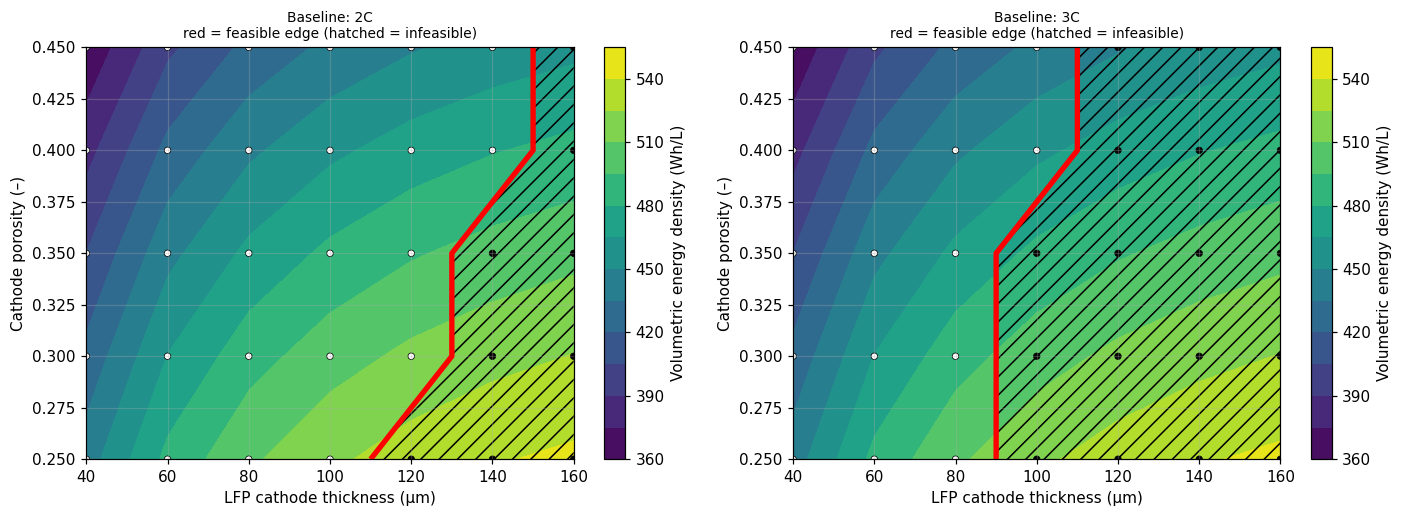

In [16]:
plot_window(base_full, feas="feasible", title="Baseline: ", fname="sec5_design_window")

## 5.2 Energy density vs thickness (one curve per porosity)
Filled marker = feasible, hollow = fails. Energy rises with thickness but flattens (foils/separator become a small share).
Lower porosity gives a higher curve. The point where a curve turns from filled to hollow is that porosity's limit.

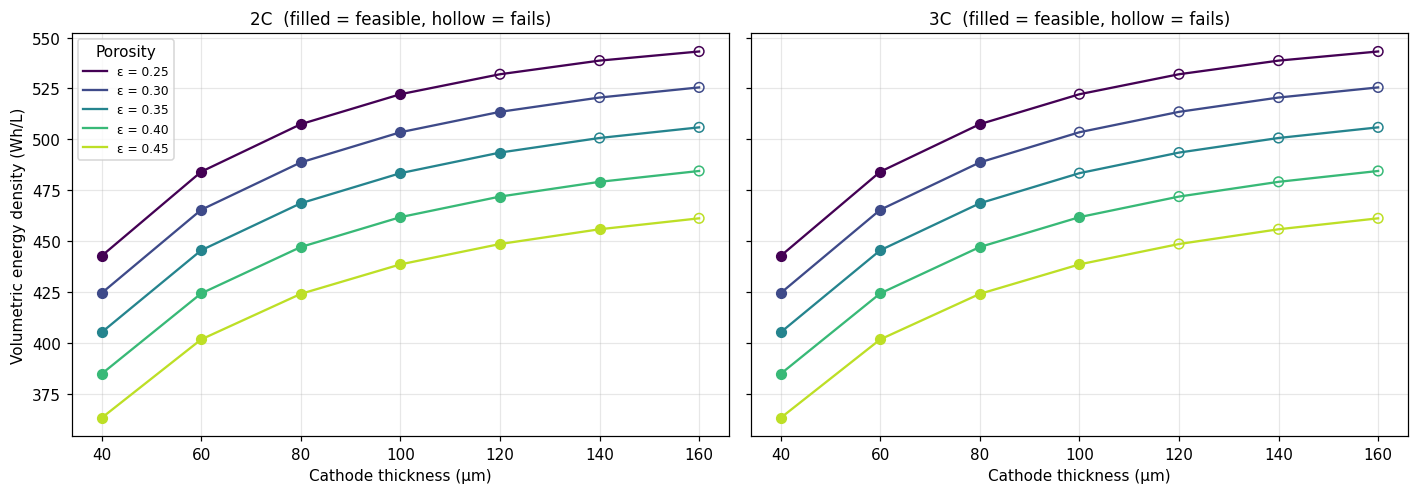

In [17]:
rates = sorted(base_full.c_rate.unique())
eps_list = sorted(base_full.porosity.unique())
colors = plt.cm.viridis(np.linspace(0, 0.9, len(eps_list)))
fig, axes = plt.subplots(1, len(rates), figsize=(6.5 * len(rates), 4.6), sharey=True, squeeze=False)
for ax, c in zip(axes[0], rates):
    for col, eps in zip(colors, eps_list):
        d = base_full[(base_full.c_rate == c) & (base_full.porosity == eps)].sort_values("thickness_um")
        ok = d.feasible.astype(bool)
        ax.plot(d.thickness_um, d.vol_energy_Wh_per_L, "-", color=col, label=f"ε = {eps:.2f}")
        ax.scatter(d.thickness_um[ok], d.vol_energy_Wh_per_L[ok], color=col, s=40, zorder=3)
        ax.scatter(d.thickness_um[~ok], d.vol_energy_Wh_per_L[~ok], facecolors="none", edgecolors=col, s=40, zorder=3)
    ax.set(title=f"{c:.0f}C  (filled = feasible, hollow = fails)", xlabel="Cathode thickness (µm)")
axes[0][0].set_ylabel("Volumetric energy density (Wh/L)"); axes[0][0].legend(title="Porosity")
show("sec5_energy_vs_thickness")

## 5.3 Maximum feasible thickness vs porosity
The *design-limit curve*: for each porosity, the thickest cathode that still passes. It rises with porosity
(more open pores → faster ion transport) and is lower for 3C than for 2C.

2C: {np.float64(0.25): 100, np.float64(0.3): 120, np.float64(0.35): 120, np.float64(0.4): 140, np.float64(0.45): 140}
3C: {np.float64(0.25): 80, np.float64(0.3): 80, np.float64(0.35): 80, np.float64(0.4): 100, np.float64(0.45): 100}


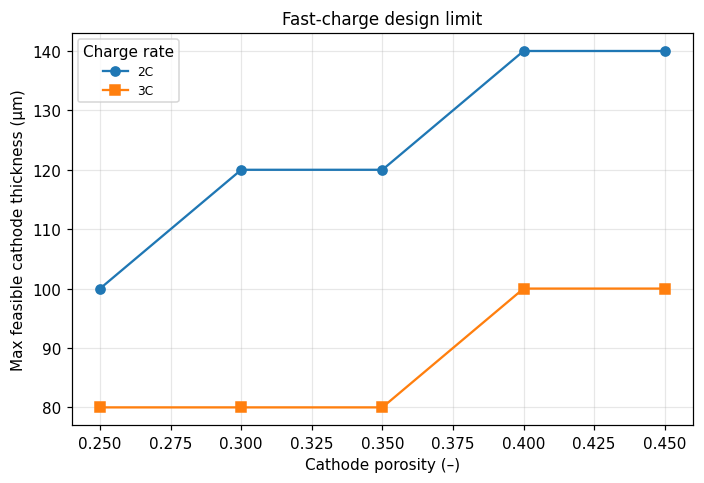

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for c, m in zip(rates, ["o", "s", "^"]):
    lim = [max_feasible_thickness(base_full[(base_full.c_rate == c) & (base_full.porosity == e)]) for e in eps_list]
    ax.plot(eps_list, np.nan_to_num(lim, nan=0), marker=m, label=f"{c:.0f}C")
    print(f"{c:.0f}C:", dict(zip(eps_list, lim)))
ax.set(xlabel="Cathode porosity (–)", ylabel="Max feasible cathode thickness (µm)", title="Fast-charge design limit")
ax.legend(title="Charge rate")
show("sec5_limit_curve")

## 5.4 Which constraint binds? (separate failure-mode maps)
* **Left column:** fraction of capacity delivered in the CC phase before the 3.65 V limit. Needs ≥ 0.8 → transport/voltage limit (mostly cathode).
* **Right column:** minimum anode potential to 80 % SOC. Needs > 0 mV → plating limit (anode + electrolyte depletion).
Compare where each map crosses its threshold to see which failure mode appears first for each design.

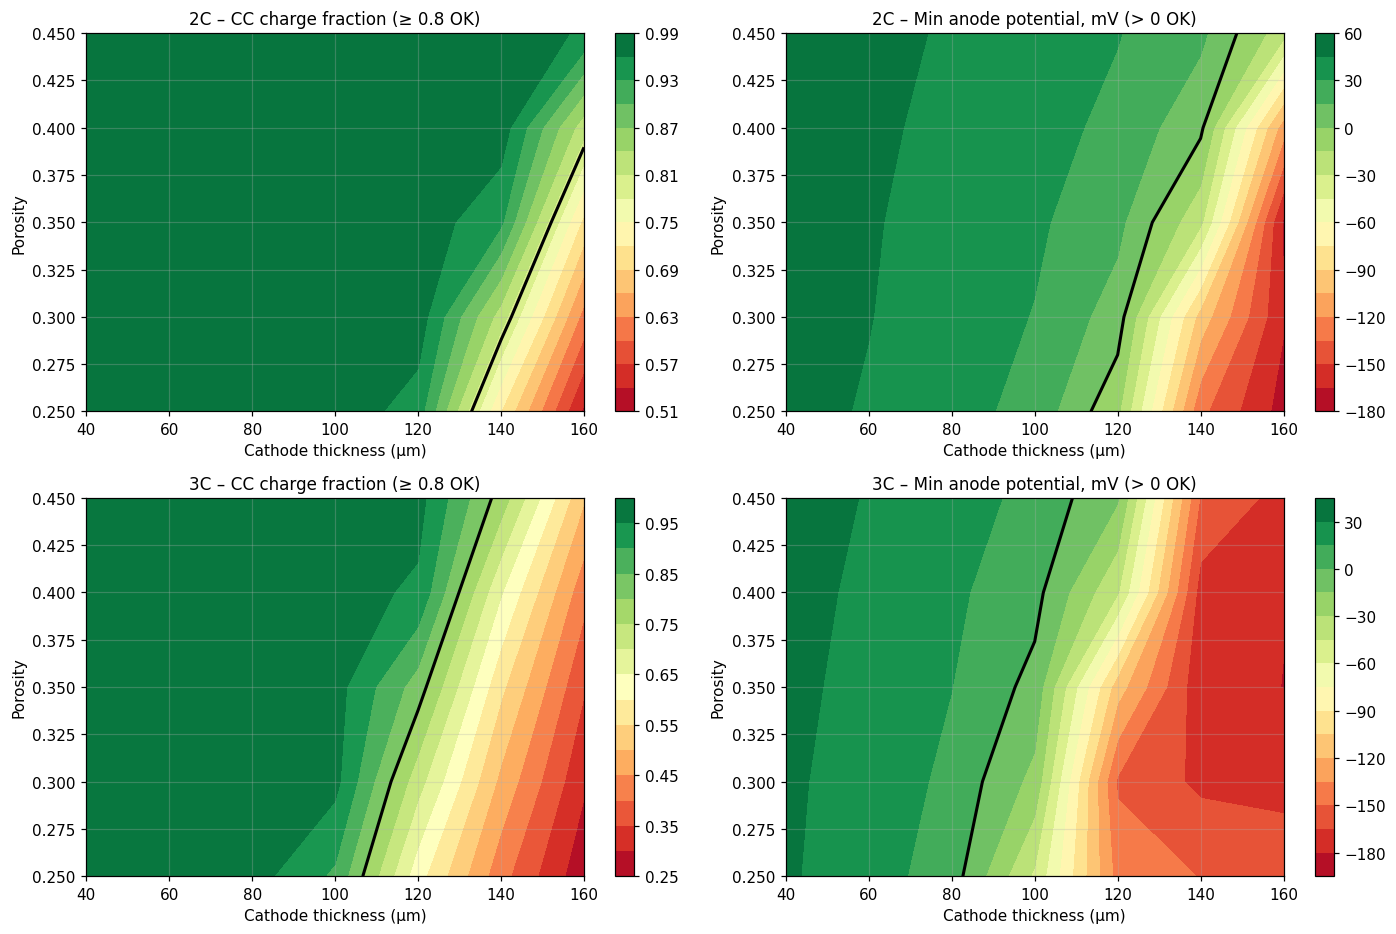

In [19]:
fig, axes = plt.subplots(len(rates), 2, figsize=(13, 4.3 * len(rates)), squeeze=False)
for i, c in enumerate(rates):
    d = base_full[base_full.c_rate == c]
    for j, (col, ttl, cmap, thr, scale) in enumerate([
            ("cc_charge_fraction", "CC charge fraction (≥ 0.8 OK)", "RdYlGn", FIXED["SOC_TARGET"], 1),
            ("min_anode_potential_V", "Min anode potential, mV (> 0 OK)", "RdYlGn", 0.0, 1e3)]):
        Z = pivot(d, col) * scale
        X, Y = np.meshgrid(Z.columns.values, Z.index.values)
        cs = axes[i][j].contourf(X, Y, Z.values, levels=15, cmap=cmap)
        fig.colorbar(cs, ax=axes[i][j])
        axes[i][j].contour(X, Y, Z.values, levels=[thr * scale], colors="k", linewidths=2)
        axes[i][j].set(title=f"{c:.0f}C – {ttl}", xlabel="Cathode thickness (µm)", ylabel="Porosity")
show("sec5_failure_mode_maps")

## 5.5 Best designs
Highest-energy designs that are feasible at **all** simulated C-rates, and the best design per individual rate.

In [20]:
g = best_design_all_rates(base_full)
if g is None:
    print("No design passes at all C-rates in the baseline. Relax N/P, anode, temperature or the thickness range.")
else:
    print("Top feasible designs passing ALL C-rates  (index = thickness µm, porosity):")
    display(g.head(8).round(1).to_frame("Wh/L"))
display(pd.DataFrame({f"{c:.0f}C": best_at_rate(base_full, c) for c in rates}).T)

Top feasible designs passing ALL C-rates  (index = thickness µm, porosity):


Wh/L
thickness_um porosity       
80           0.25      507.4
             0.30      488.6
60           0.25      484.1
80           0.35      468.6
60           0.30      465.4
100          0.40      461.7
80           0.40      447.1
60           0.35      445.5

,energy,thickness,porosity
2C,522.129562,100.0,0.25
3C,507.421977,80.0,0.25


## 5.6 Inside the cell: *why* thick electrodes struggle
We compare a **thin (60 µm)** and a **thick (140 µm)** cathode at 3C, both porosity 0.35:
* **Electrolyte concentration** across the cell at the end of the CC phase (left side = anode, right side = cathode) –
  steep gradients and near-zero concentration indicate electrolyte depletion (the tortuosity / transport limit).
* **Anode potential** during charge – the thick cell dives lower and earlier (plating risk).
* **Terminal voltage** – the thick cell reaches 3.65 V sooner, so less capacity is delivered in the CC phase.

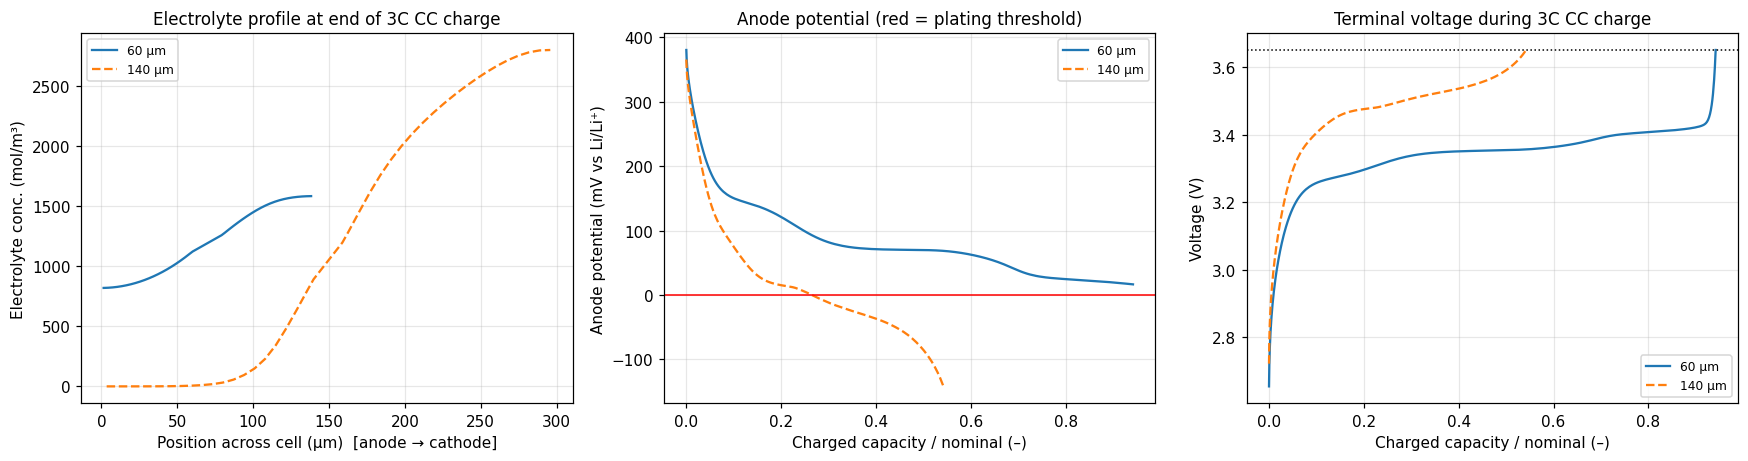

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for (L, eps), ls in zip([(60, 0.35), (140, 0.35)], ["-", "--"]):
    res, sol = run_design(L, eps, 3.0, return_sol=True)
    cap = res["cap_Ah"]
    cc = sol.cycles[0].steps[2]
    x = cc["x [m]"].entries[:, -1] * 1e6
    axes[0].plot(x, cc["Electrolyte concentration [mol.m-3]"].entries[:, -1], ls, label=f"{L} µm")
    qfrac = np.abs(cc["Discharge capacity [A.h]"].entries - cc["Discharge capacity [A.h]"].entries[0]) / cap
    axes[1].plot(qfrac, anode_potential(cc) * 1e3, ls, label=f"{L} µm")
    axes[2].plot(qfrac, cc["Voltage [V]"].entries, ls, label=f"{L} µm")
axes[0].set(xlabel="Position across cell (µm)  [anode → cathode]", ylabel="Electrolyte conc. (mol/m³)",
            title="Electrolyte profile at end of 3C CC charge")
axes[1].axhline(0, color="r", lw=1); axes[1].set(xlabel="Charged capacity / nominal (–)", ylabel="Anode potential (mV vs Li/Li⁺)",
            title="Anode potential (red = plating threshold)")
axes[2].axhline(FIXED["V_MAX"], color="k", ls=":", lw=1); axes[2].set(xlabel="Charged capacity / nominal (–)", ylabel="Voltage (V)",
            title="Terminal voltage during 3C CC charge")
for a in axes: a.legend()
show("sec5_inside_the_cell")

---
# 6. Extension 1 – Tortuosity (Bruggeman exponent) sensitivity
The baseline assumes *b* = 1.5, which is optimistic for real LFP electrodes (carbon-binder domains, irregular pores).
Larger *b* → higher tortuosity (τ = ε^(1−b)) → slower electrolyte transport. We re-run the coarse grid for *b* = 1.5, 2.0, 2.5
and watch the feasible window shrink.

In [22]:
BRUG_VALUES = [1.5, 2.0, 2.5]
fam_brug = {}
for b in BRUG_VALUES:
    if b == BASE_CFG["bruggeman"]:
        fam_brug[b] = coarse(base_full)                    # reuse baseline results
    else:
        fam_brug[b] = run_sweep(GRID_T, GRID_E, C_RATES, {"bruggeman": b}, label=f"brug_{b}")

tort = pd.DataFrame({"porosity": GRID_E})
for b in BRUG_VALUES:
    tort[f"tortuosity (b={b})"] = tort.porosity ** (1 - b)
print("Tortuosity factor τ = ε^(1−b) for each porosity:")
display(tort.round(2))

brug_2.0:   0%|          | 0/36 [00:00<?, ?it/s]

brug_2.0: 36 runs, 0 failed


brug_2.5:   0%|          | 0/36 [00:00<?, ?it/s]

2026-11-17 10:46:40.573 - [ERROR] callbacks.on_experiment_error(226): Simulation error: input set 0: IDA_ERR_FAIL: Error test failures occurred too many times during one step or minimum step size was reached
ERROR:pybamm.logger:Simulation error: input set 0: IDA_ERR_FAIL: Error test failures occurred too many times during one step or minimum step size was reached
2026-11-17 10:46:43.231 - [ERROR] callbacks.on_experiment_error(226): Simulation error: input set 0: IDA_ERR_FAIL: Error test failures occurred too many times during one step or minimum step size was reached
ERROR:pybamm.logger:Simulation error: input set 0: IDA_ERR_FAIL: Error test failures occurred too many times during one step or minimum step size was reached


brug_2.5: 36 runs, 0 failed
Tortuosity factor τ = ε^(1−b) for each porosity:


,porosity,tortuosity (b=1.5),tortuosity (b=2.0),tortuosity (b=2.5)
0,0.25,2.00,4.00,8.00
1,0.35,1.69,2.86,4.83
2,0.45,1.49,2.22,3.31


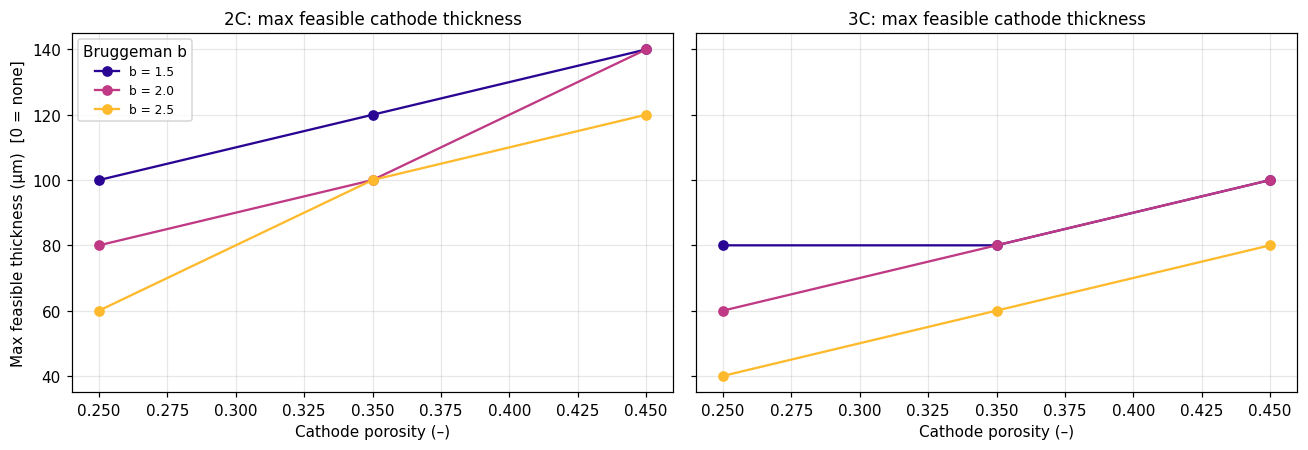

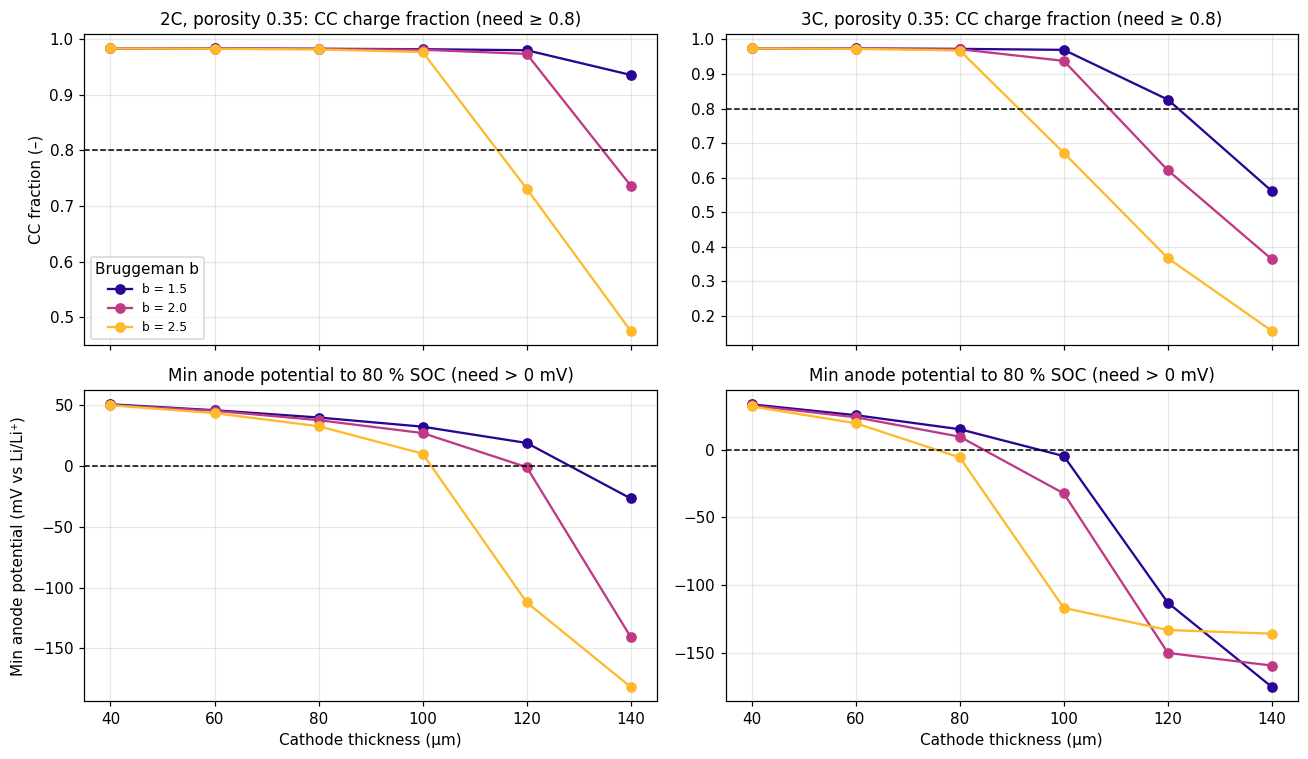

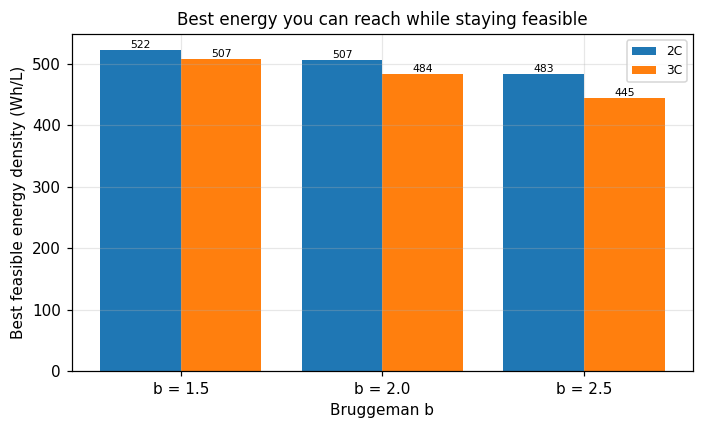

,Bruggeman b,C-rate,max feasible thickness (µm),best feasible Wh/L,at thickness (µm),at porosity
0,b = 1.5,2.0,140,522.13,100,0.25
1,b = 1.5,3.0,100,507.42,80,0.25
2,b = 2.0,2.0,140,506.71,80,0.25
3,b = 2.0,3.0,100,483.71,60,0.25
4,b = 2.5,2.0,120,482.95,60,0.25
5,b = 2.5,3.0,80,445.11,60,0.35


In [23]:
tbl_brug = family_report(fam_brug, "Bruggeman b", lambda v: f"b = {v}", tag="sec6_bruggeman")
display(tbl_brug.round(2))

**How to read:** each line/bar group is one tortuosity level. A higher *b* moves the limit curves down (thinner electrodes only),
worsens the CC fraction at the same thickness, and lowers the best feasible energy. If the lines drop a lot, the design
is *transport-limited*; thick electrodes would then need higher porosity or lower tortuosity (e.g. aligned pores, laser structuring).

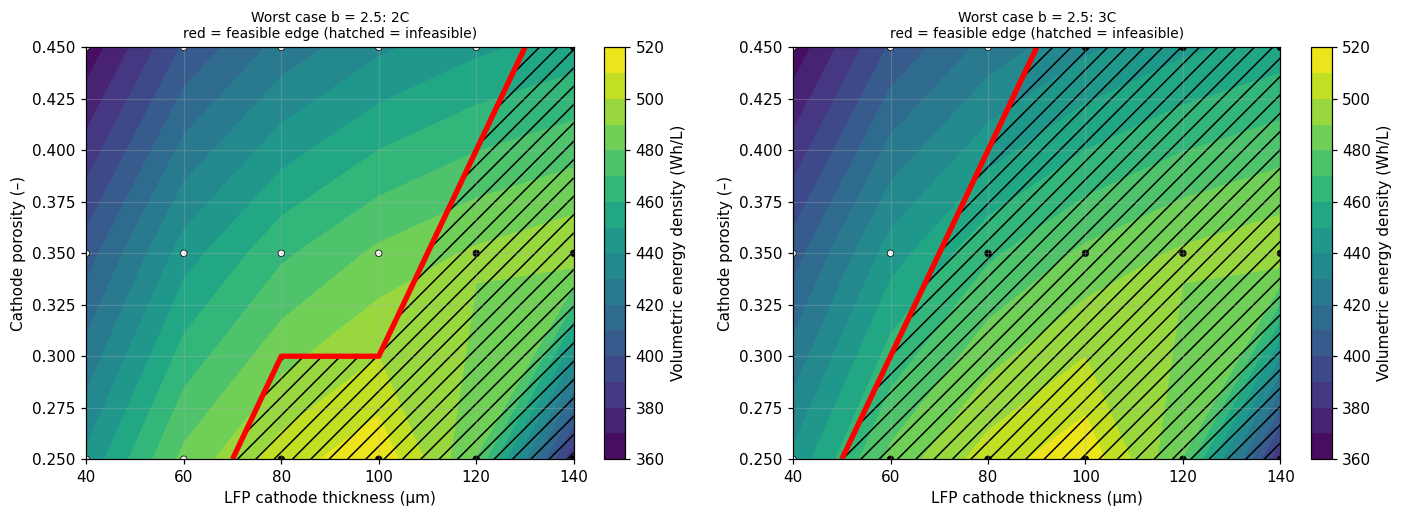

In [24]:
plot_window(pd.concat([d.assign(bruggeman=b) for b, d in fam_brug.items() if b == BRUG_VALUES[-1]]),
            feas="feasible", title=f"Worst case b = {BRUG_VALUES[-1]}: ", fname="sec6_window_worst_case")

---
# 7. Extension 2 – Temperature sensitivity
Plating risk rises sharply at low temperature because diffusion and reaction kinetics slow down while the
anode is pushed to lower potentials. We re-run the coarse grid at 45, 25, 10 and 0 °C.

temp_45C:   0%|          | 0/36 [00:00<?, ?it/s]

temp_45C: 36 runs, 0 failed


temp_10C:   0%|          | 0/36 [00:00<?, ?it/s]

temp_10C: 36 runs, 0 failed


temp_0C:   0%|          | 0/36 [00:00<?, ?it/s]

temp_0C: 36 runs, 0 failed


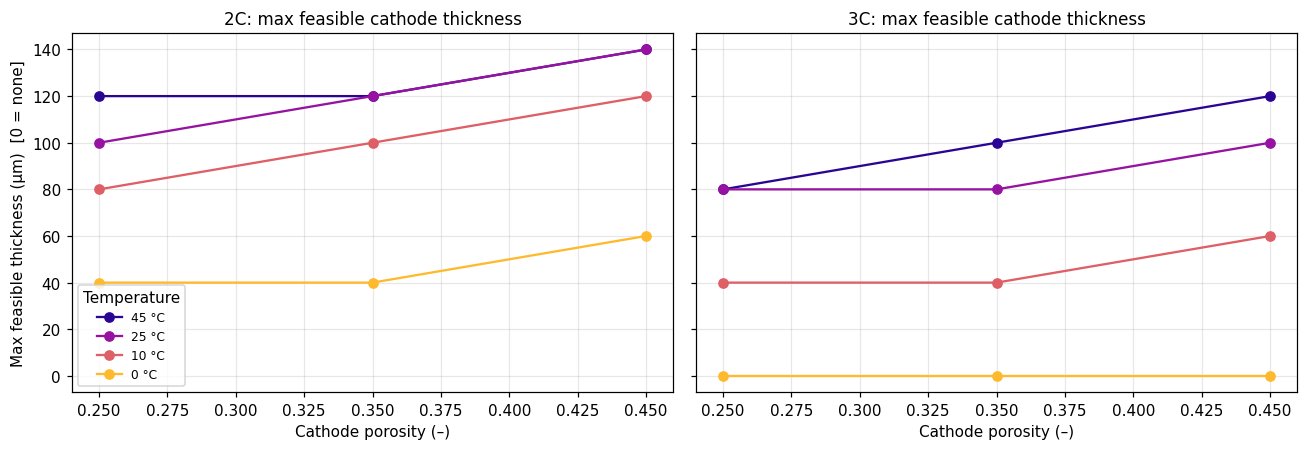

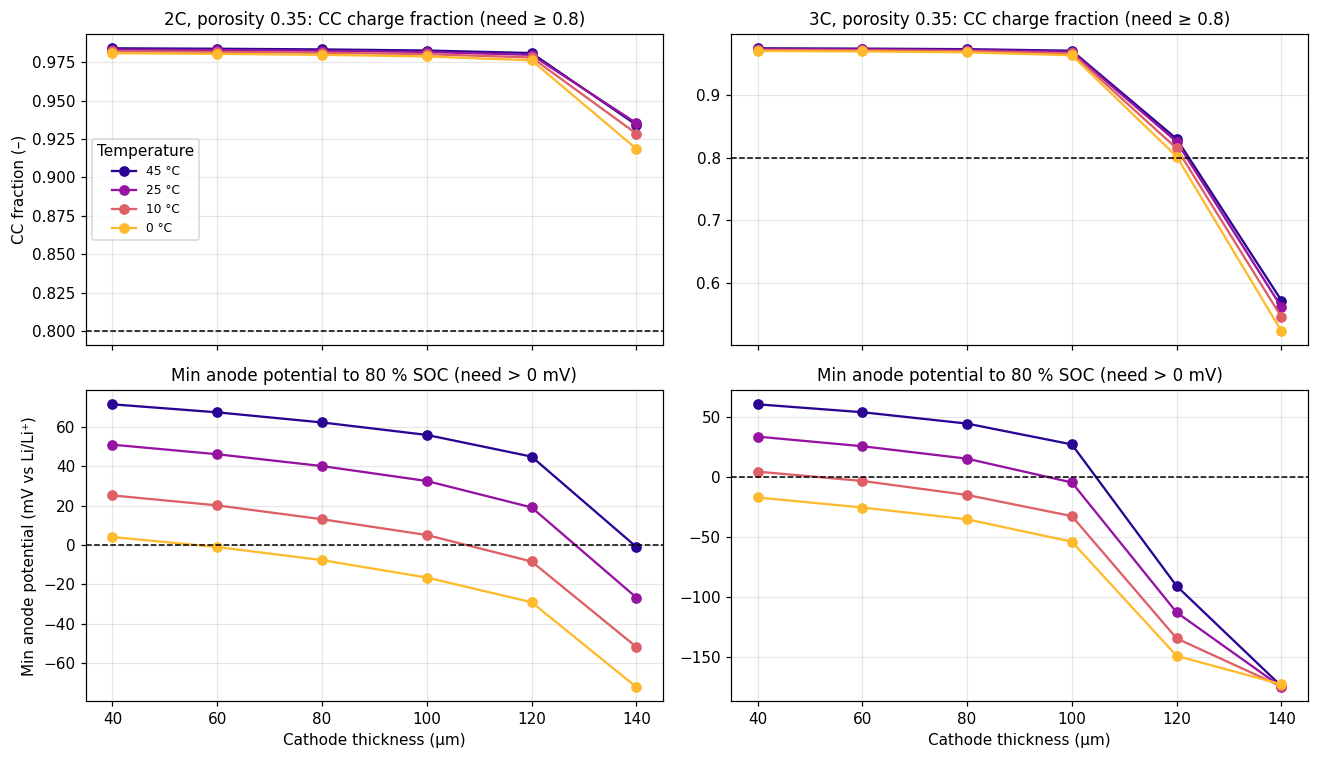

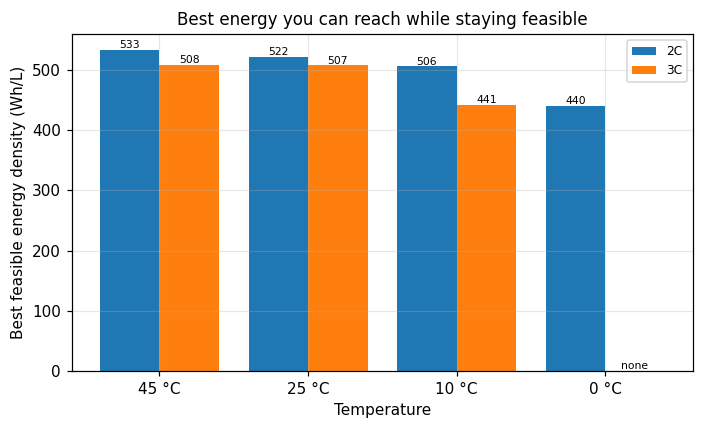

,Temperature,C-rate,max feasible thickness (µm),best feasible Wh/L,at thickness (µm),at porosity
0,45 °C,2.0,140.0,532.69,120.0,0.25
1,45 °C,3.0,120.0,508.23,80.0,0.25
2,25 °C,2.0,140.0,522.13,100.0,0.25
3,25 °C,3.0,100.0,507.42,80.0,0.25
4,10 °C,2.0,120.0,505.93,80.0,0.25
5,10 °C,3.0,60.0,441.37,40.0,0.25
6,0 °C,2.0,60.0,439.68,40.0,0.25
7,0 °C,3.0,NaN,NaN,NaN,NaN


In [25]:
TEMPS_C = [45, 25, 10, 0]
fam_temp = {}
for T in TEMPS_C:
    if T == 25:
        fam_temp[T] = coarse(base_full)
    else:
        fam_temp[T] = run_sweep(GRID_T, GRID_E, C_RATES, {"T_K": 273.15 + T}, label=f"temp_{T}C")

tbl_temp = family_report(fam_temp, "Temperature", lambda v: f"{v} °C", tag="sec7_temperature")
display(tbl_temp.round(2))

### Plating margin vs temperature for a reference design
One fixed design (80 µm, ε = 0.35) across temperature at each C-rate. Where the curve crosses 0 mV the design starts to plate.

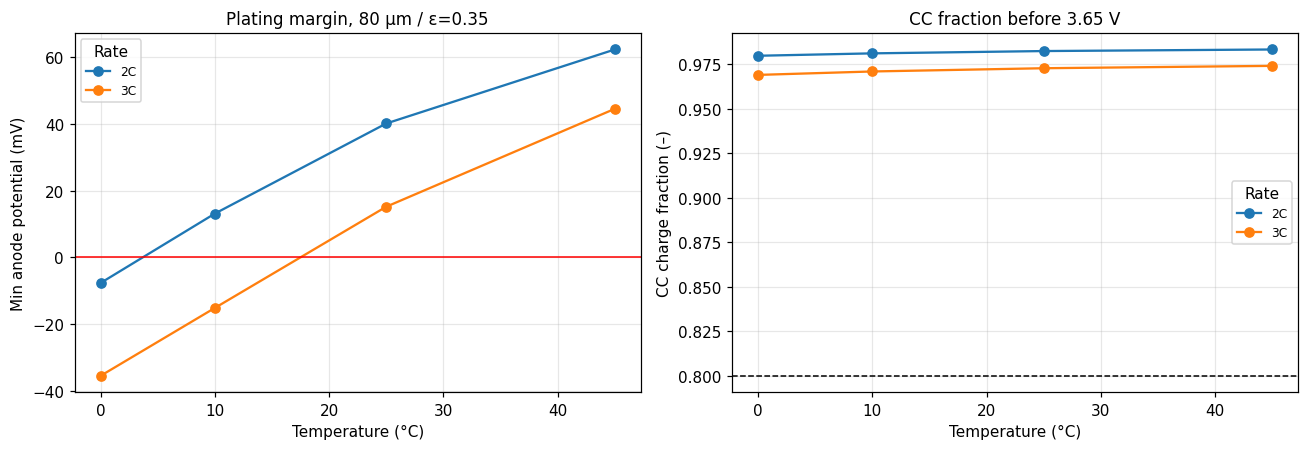

In [26]:
ref_L, ref_eps = 80, 0.35
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for c in C_RATES:
    xs, eta, cc_ = [], [], []
    for T, df in sorted(fam_temp.items()):
        r = df[(df.c_rate == c) & (df.thickness_um == ref_L) & (df.porosity == ref_eps)]
        if len(r): xs.append(T); eta.append(r.min_anode_potential_V.iloc[0] * 1e3); cc_.append(r.cc_charge_fraction.iloc[0])
    axes[0].plot(xs, eta, "o-", label=f"{c:.0f}C"); axes[1].plot(xs, cc_, "o-", label=f"{c:.0f}C")
axes[0].axhline(0, color="r", lw=1); axes[0].set(xlabel="Temperature (°C)", ylabel="Min anode potential (mV)",
        title=f"Plating margin, {ref_L} µm / ε={ref_eps}")
axes[1].axhline(FIXED["SOC_TARGET"], color="k", ls="--", lw=1); axes[1].set(xlabel="Temperature (°C)",
        ylabel="CC charge fraction (–)", title="CC fraction before 3.65 V")
for a in axes: a.legend(title="Rate")
show("sec7_plating_margin_vs_T")

---
# 8. Extension 3 – Anode design sensitivity
So far the *anode* has been fixed (N/P = 1.2, graphite particles scaled to 0.25× the stock radius). In reality the anode can be
the plating bottleneck. We test two levers:
1. **Graphite particle radius** (`anode_r_scale`): smaller particles → faster solid diffusion + more reactive area.
2. **N/P ratio** (`np_ratio`): more anode capacity → lower lithiation level & lower current density, but *lower energy density*.

## 8.1 Particle-size effect on the whole window
Coarse grid at N/P = 1.2 for graphite radius scale 1.0 (stock), 0.5 and 0.25 (baseline).

anode_r_1.0:   0%|          | 0/36 [00:00<?, ?it/s]

anode_r_1.0: 36 runs, 0 failed


anode_r_0.5:   0%|          | 0/36 [00:00<?, ?it/s]

anode_r_0.5: 36 runs, 0 failed


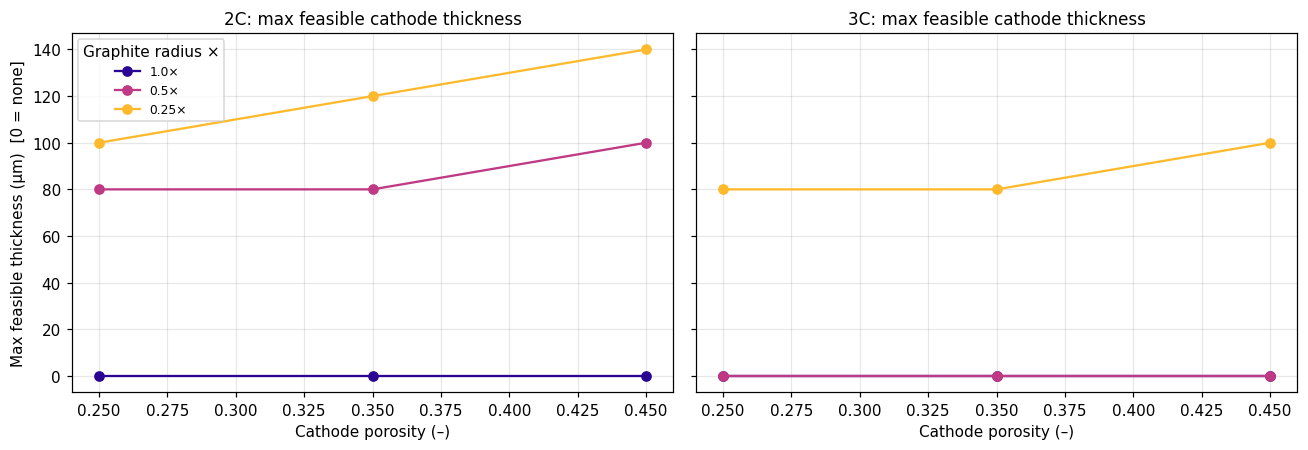

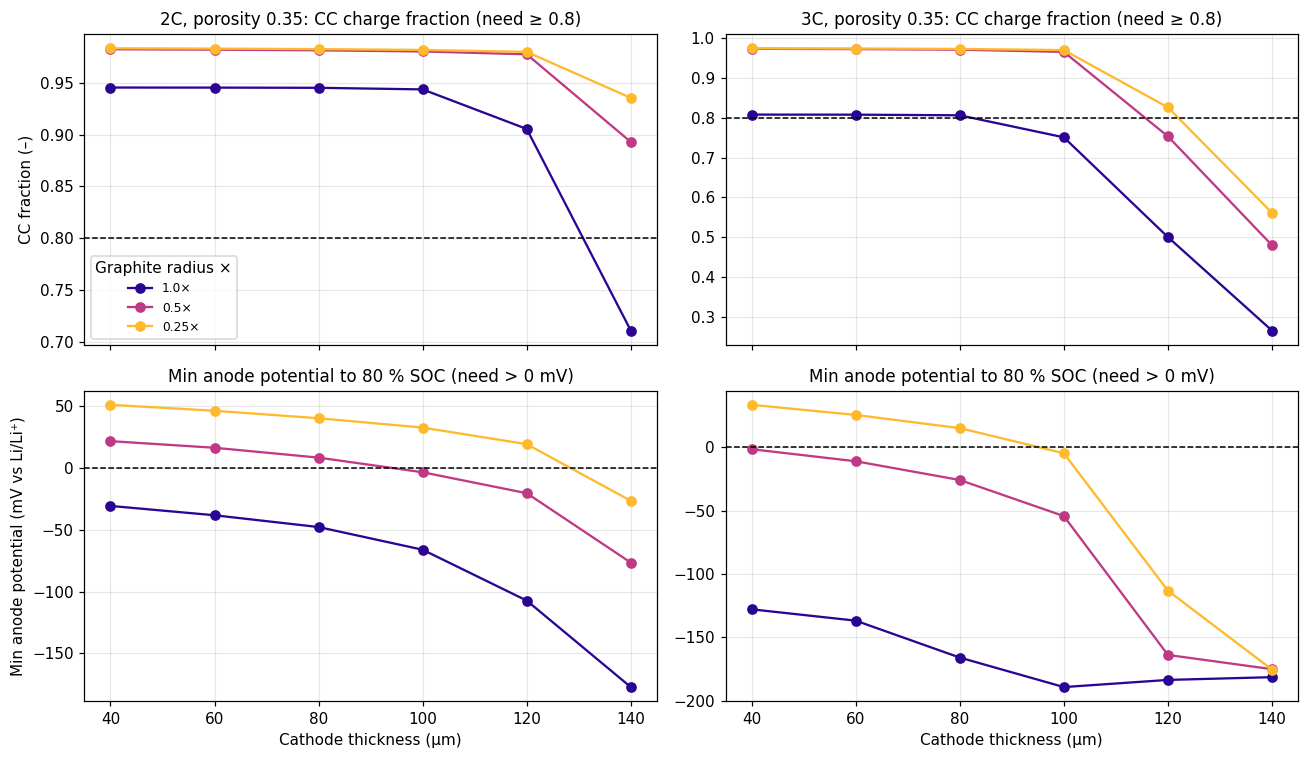

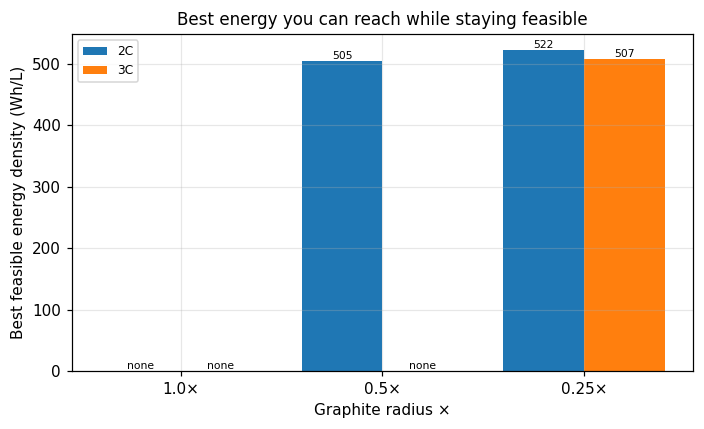

,Graphite radius ×,C-rate,max feasible thickness (µm),best feasible Wh/L,at thickness (µm),at porosity
0,1.0×,2.0,NaN,NaN,NaN,NaN
1,1.0×,3.0,NaN,NaN,NaN,NaN
2,0.5×,2.0,100.0,504.58,80.0,0.25
3,0.5×,3.0,NaN,NaN,NaN,NaN
4,0.25×,2.0,140.0,522.13,100.0,0.25
5,0.25×,3.0,100.0,507.42,80.0,0.25


In [27]:
R_VALUES = [1.0, 0.5, 0.25]
fam_r = {}
for r in R_VALUES:
    if r == BASE_CFG["anode_r_scale"]:
        fam_r[r] = coarse(base_full)
    else:
        fam_r[r] = run_sweep(GRID_T, GRID_E, C_RATES, {"anode_r_scale": r}, label=f"anode_r_{r}")

tbl_r = family_report(fam_r, "Graphite radius ×", lambda v: f"{v}×", tag="sec8_anode_radius")
display(tbl_r.round(2))

## 8.2 N/P ratio × particle size at fixed reference cathodes (3C)
Two reference cathodes are tested at 3C. Each cell shows the result for one anode setting:
* **Plating margin** (mV) – green/positive = safe
* **CC fraction** – ≥ 0.8 required
* **Energy density** – the *cost* of a larger N/P (thicker anode)

anode grid 80µm/ε0.3:   0%|          | 0/25 [00:00<?, ?it/s]

anode grid 120µm/ε0.35:   0%|          | 0/25 [00:00<?, ?it/s]

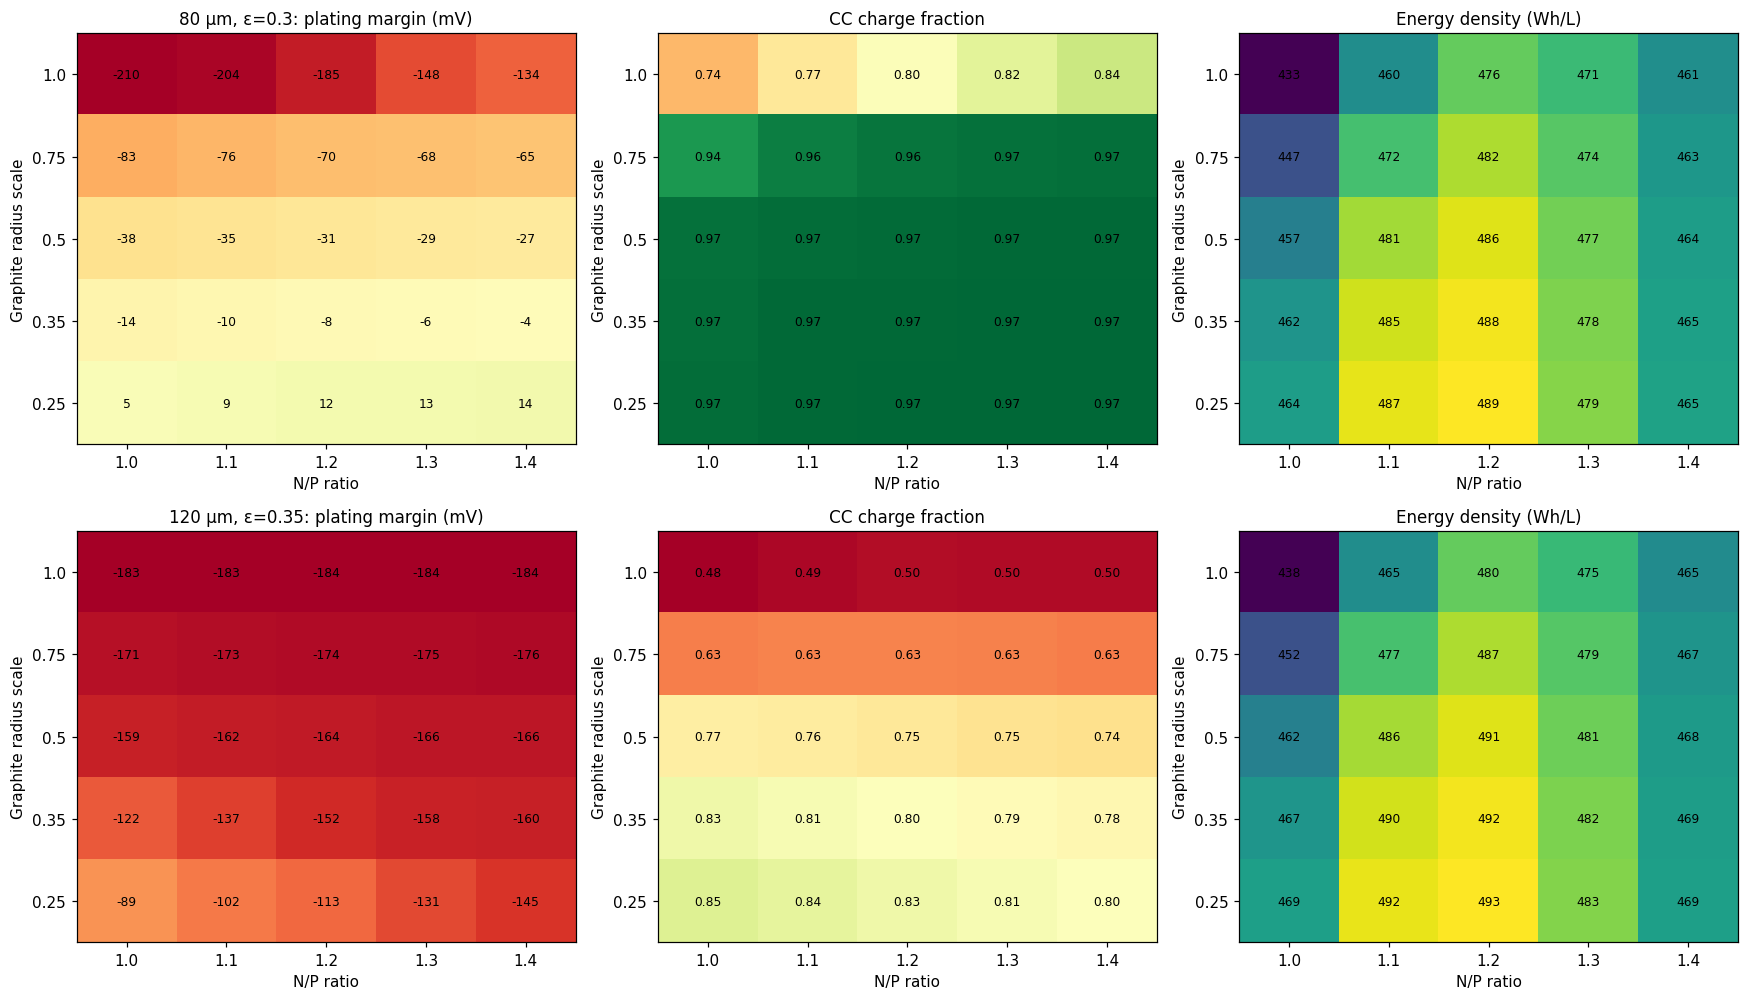

In [28]:
NP_LIST = [1.0, 1.1, 1.2, 1.3, 1.4]
R_LIST  = [1.0, 0.75, 0.5, 0.35, 0.25]
REF_DESIGNS = [(80, 0.30), (120, 0.35)]
RATE_REF = 3.0

def anode_grid(L, eps):
    path = f"results/anode_grid_{L}_{eps}.csv"
    if USE_CACHE and os.path.exists(path): return pd.read_csv(path)
    rows = []
    for npr, r in tqdm(list(itertools.product(NP_LIST, R_LIST)), desc=f"anode grid {L}µm/ε{eps}"):
        try:
            res = run_design(L, eps, RATE_REF, {"np_ratio": npr, "anode_r_scale": r})
        except Exception:
            res = dict(np_ratio=npr, anode_r_scale=r, min_anode_potential_V=np.nan, cc_charge_fraction=np.nan, vol_energy_Wh_per_L=np.nan)
        rows.append(res)
    out = pd.DataFrame(rows); out.to_csv(path, index=False); return out

anode_results = {ref: anode_grid(*ref) for ref in REF_DESIGNS}

def heat(ax, d, col, scale, title, fmt, cmap, center=None):
    M = d.pivot_table(index="anode_r_scale", columns="np_ratio", values=col) * scale
    M = M.sort_index(ascending=False)
    kw = dict(cmap=cmap, aspect="auto")
    if center is not None:
        span = np.nanmax(np.abs(M.values - center)); kw.update(vmin=center - span, vmax=center + span)
    im = ax.imshow(M.values, **kw)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M.values[i, j]), ha="center", va="center", fontsize=8)
    ax.set(title=title, xlabel="N/P ratio", ylabel="Graphite radius scale"); ax.grid(False)
    return im

fig, axes = plt.subplots(len(REF_DESIGNS), 3, figsize=(16, 4.6 * len(REF_DESIGNS)), squeeze=False)
for i, ((L, eps), d) in enumerate(anode_results.items()):
    heat(axes[i][0], d, "min_anode_potential_V", 1e3, f"{L} µm, ε={eps}: plating margin (mV)", "{:.0f}", "RdYlGn", center=0)
    heat(axes[i][1], d, "cc_charge_fraction", 1, "CC charge fraction", "{:.2f}", "RdYlGn", center=FIXED["SOC_TARGET"])
    heat(axes[i][2], d, "vol_energy_Wh_per_L", 1, "Energy density (Wh/L)", "{:.0f}", "viridis")
show("sec8_np_vs_radius_heatmaps")

**How to read:** each cell is one anode design. Rows = graphite particle size, columns = N/P ratio.
* **Particle size is the strong lever.** Moving *up* (larger particles) rapidly worsens the plating margin and the CC fraction;
  moving *down* (smaller particles) improves both. If particle size dominates, the real bottleneck is the **anode**, not the LFP cathode.
* **N/P is a weak lever and has an optimum.** At N/P ≤ ~1.1 the anode limits the usable capacity (we cycle only 90 % of the graphite),
  so energy density drops; above ~1.2 the extra graphite thickness only adds volume (energy falls) and can even *reduce* the
  plating margin for the thick cathode, because the ions must cross a thicker anode.
* (These observations are from the default settings; re-check them if you change the parameters.)

---
# 9. Extension 4 – Charging-time analysis (CC-CV, time to 80 % SOC)
A real charger uses **CC-CV**: constant current until 3.65 V, then constant voltage as the current tapers.
If the cell hits the voltage limit early (thick/dense electrode), the CV phase adds time. We measure:
* `t80_min` – actual time to 80 % SOC (CC + CV)
* `t80_ideal_min` – time if CC could run all the way (best case)
* `t80_penalty = t80 / ideal` – the transport-limited slowdown

**Relaxed feasibility** (`feasible_ccv`): plating-free **and** `t80 ≤ 1.25 × ideal`. This is more realistic than the strict
"80 % inside CC" criterion, so the CC-CV window is usually larger.

## 9.1 Time to 80 % SOC vs thickness

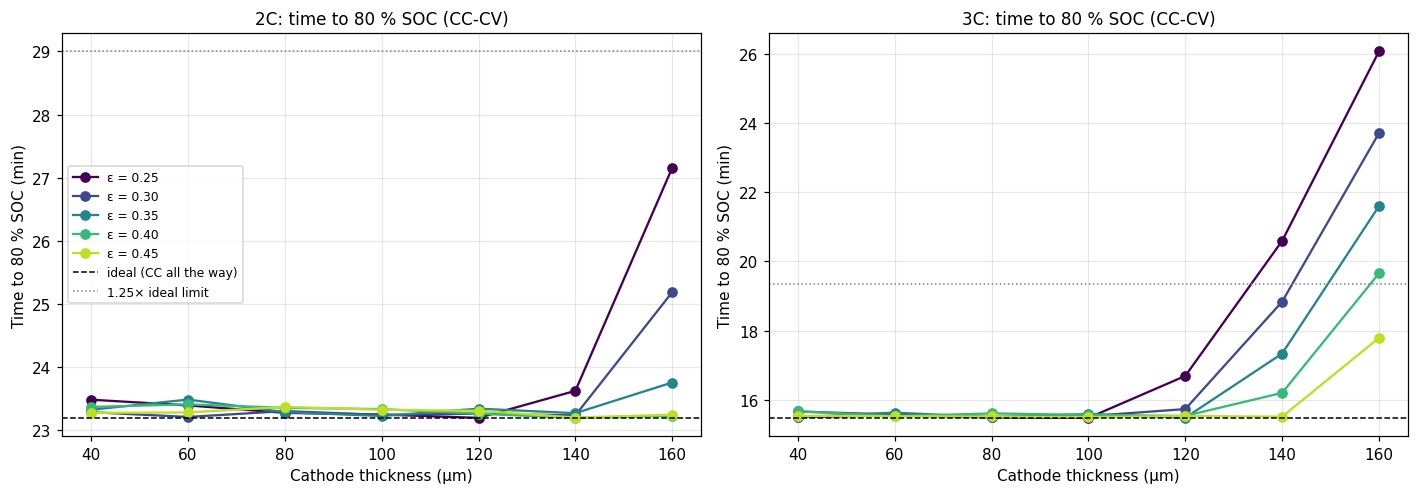

In [29]:
fig, axes = plt.subplots(1, len(rates), figsize=(6.5 * len(rates), 4.6), sharey=False, squeeze=False)
for ax, c in zip(axes[0], rates):
    for col, eps in zip(colors, eps_list):
        d = base_full[(base_full.c_rate == c) & (base_full.porosity == eps)].sort_values("thickness_um")
        ax.plot(d.thickness_um, d.t80_min, "o-", color=col, label=f"ε = {eps:.2f}")
    ideal = base_full[base_full.c_rate == c].t80_ideal_min.median()
    ax.axhline(ideal, color="k", ls="--", lw=1, label="ideal (CC all the way)")
    ax.axhline(FIXED["T80_TOLERANCE"] * ideal, color="gray", ls=":", lw=1, label=f"{FIXED['T80_TOLERANCE']}× ideal limit")
    ax.set(title=f"{c:.0f}C: time to 80 % SOC (CC-CV)", xlabel="Cathode thickness (µm)", ylabel="Time to 80 % SOC (min)")
axes[0][0].legend()
show("sec9_t80_vs_thickness")

## 9.2 Energy vs charging time (design trade-off / Pareto view)
Each dot is a design. **Top-left is best** (high energy, short charge). Filled dots = plating-free; hollow = plating.
Designs stacked at the ideal time reach 80 % within the CC phase; points to the right pay a CV time penalty.

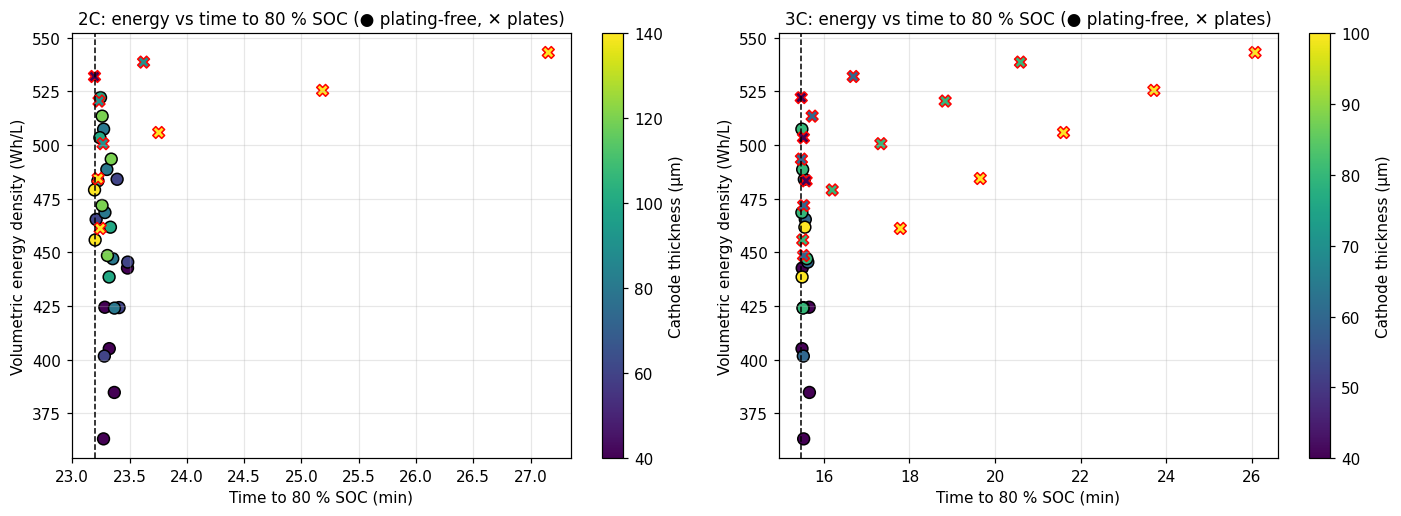

In [30]:
fig, axes = plt.subplots(1, len(rates), figsize=(6.5 * len(rates), 4.8), squeeze=False)
for ax, c in zip(axes[0], rates):
    d = base_full[(base_full.c_rate == c) & base_full.t80_min.notna()]
    pf = d.plating_free.astype(bool)
    sc = ax.scatter(d.t80_min[pf], d.vol_energy_Wh_per_L[pf], c=d.thickness_um[pf], cmap="viridis", s=60, edgecolors="k")
    ax.scatter(d.t80_min[~pf], d.vol_energy_Wh_per_L[~pf], c=d.thickness_um[~pf], cmap="viridis", s=60, marker="X", edgecolors="r")
    fig.colorbar(sc, ax=ax, label="Cathode thickness (µm)")
    ax.axvline(base_full[base_full.c_rate == c].t80_ideal_min.median(), color="k", ls="--", lw=1)
    ax.set(title=f"{c:.0f}C: energy vs time to 80 % SOC (● plating-free, ✕ plates)", xlabel="Time to 80 % SOC (min)",
           ylabel="Volumetric energy density (Wh/L)")
show("sec9_energy_vs_t80")

## 9.3 Strict (CC) window vs relaxed (CC-CV) window
Red solid = strict criterion (≥ 80 % delivered in CC). Blue dashed = relaxed CC-CV criterion.
**If the two lines coincide, plating — not the voltage limit — is what sets the boundary**: allowing a CV tail cannot
help a design whose anode already plates before 80 % SOC. A gap between them would mean the voltage limit is the binding constraint.

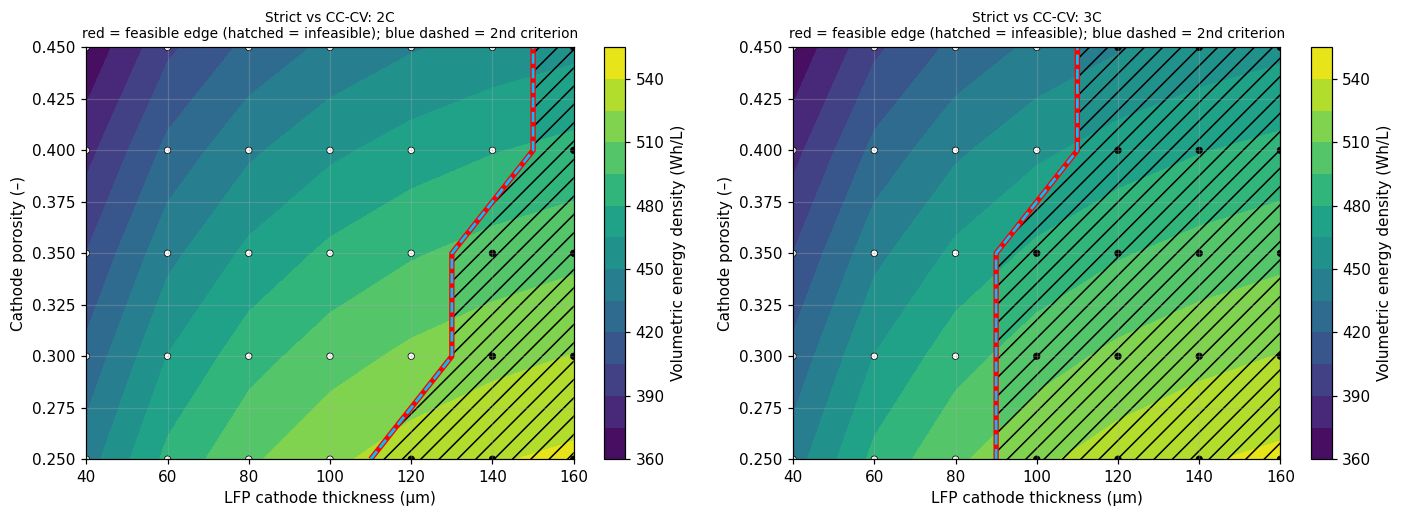

In [31]:
plot_window(base_full, feas="feasible", overlay="feasible_ccv", title="Strict vs CC-CV: ", fname="sec9_window_strict_vs_ccv")

In [32]:
rows = []
for c in rates:
    for name, feas in [("strict (CC)", "feasible"), ("relaxed (CC-CV)", "feasible_ccv")]:
        b = best_at_rate(base_full, c, feas)
        lim = max([max_feasible_thickness(base_full[(base_full.c_rate == c) & (base_full.porosity == e)], feas) for e in eps_list])
        rows.append({"C-rate": c, "criterion": name, "max feasible thickness (µm)": lim, "best Wh/L": b["energy"],
                     "at thickness (µm)": b["thickness"], "at porosity": b["porosity"]})
tbl_ccv = pd.DataFrame(rows)
display(tbl_ccv.round(2))

,C-rate,criterion,max feasible thickness (µm),best Wh/L,at thickness (µm),at porosity
0,2.0,strict (CC),140,522.13,100,0.25
1,2.0,relaxed (CC-CV),140,522.13,100,0.25
2,3.0,strict (CC),100,507.42,80,0.25
3,3.0,relaxed (CC-CV),100,507.42,80,0.25


## 9.4 Which constraint sets the boundary? (plating vs transport/voltage)
Red solid = **plating-free** window alone. Blue dashed = **≥ 80 % in CC** (voltage/transport) window alone.
Whichever line is further left is the binding constraint at that porosity.

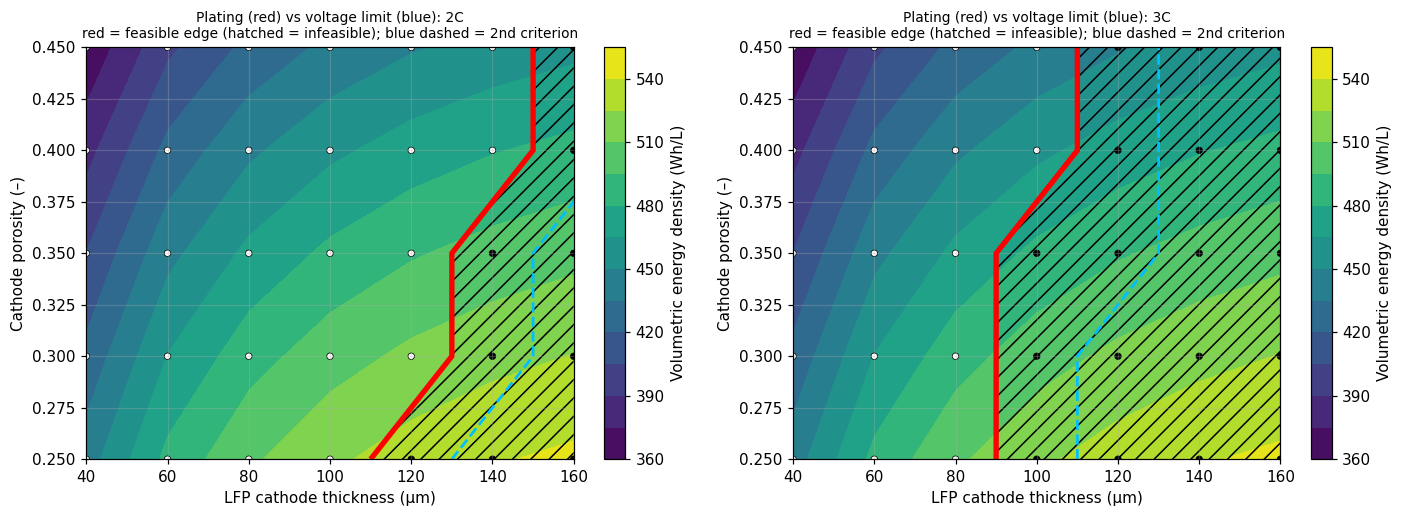

In [33]:
plot_window(base_full, feas="plating_free", overlay="meets_charge_target", title="Plating (red) vs voltage limit (blue): ",
            fname="sec9_which_constraint_binds")

In [34]:
rows = []
for c in rates:
    for name, feas in [("plating-free only", "plating_free"), ("≥80 % in CC only", "meets_charge_target")]:
        lim = [max_feasible_thickness(base_full[(base_full.c_rate == c) & (base_full.porosity == e)], feas) for e in eps_list]
        rows.append({"C-rate": c, "constraint": name, **{f"ε={e:.2f}": l for e, l in zip(eps_list, lim)}})
display(pd.DataFrame(rows))

,C-rate,constraint,ε=0.25,ε=0.30,ε=0.35,ε=0.40,ε=0.45
0,2.0,plating-free only,100,120,120,140,140
1,2.0,≥80 % in CC only,120,140,140,160,160
2,3.0,plating-free only,80,80,80,100,100
3,3.0,≥80 % in CC only,100,100,120,120,120


---
# 10. Cross-scenario summary, export and download

In [35]:
scenarios = {"baseline (b=1.5, 25 °C, N/P 1.2, r×0.25)": coarse(base_full)}
for b, d in fam_brug.items():
    if b != BASE_CFG["bruggeman"]: scenarios[f"Bruggeman b={b}"] = d
for T, d in fam_temp.items():
    if T != 25: scenarios[f"Temperature {T} °C"] = d
for r, d in fam_r.items():
    if r != BASE_CFG["anode_r_scale"]: scenarios[f"Graphite radius ×{r}"] = d

rows = []
for name, d in scenarios.items():
    for c in C_RATES:
        b = best_at_rate(d, c)
        lim = max([max_feasible_thickness(d[(d.c_rate == c) & (d.porosity == e)]) for e in GRID_E])
        rows.append({"scenario": name, "C-rate": c, "max feasible thickness (µm)": lim,
                     "best feasible Wh/L": b["energy"], "at thickness (µm)": b["thickness"], "at porosity": b["porosity"]})
summary = pd.DataFrame(rows)
display(summary.round(2))
summary.to_csv("results/summary_all_scenarios.csv", index=False)

,scenario,C-rate,max feasible thickness (µm),best feasible Wh/L,at thickness (µm),at porosity
0,"baseline (b=1.5, 25 °C, N/P 1.2, r×0.25)",2.0,140.0,522.13,100.0,0.25
1,"baseline (b=1.5, 25 °C, N/P 1.2, r×0.25)",3.0,100.0,507.42,80.0,0.25
2,Bruggeman b=2.0,2.0,140.0,506.71,80.0,0.25
3,Bruggeman b=2.0,3.0,100.0,483.71,60.0,0.25
4,Bruggeman b=2.5,2.0,120.0,482.95,60.0,0.25
5,Bruggeman b=2.5,3.0,80.0,445.11,60.0,0.35
6,Temperature 45 °C,2.0,140.0,532.69,120.0,0.25
7,Temperature 45 °C,3.0,120.0,508.23,80.0,0.25
8,Temperature 10 °C,2.0,120.0,505.93,80.0,0.25
9,Temperature 10 °C,3.0,60.0,441.37,40.0,0.25


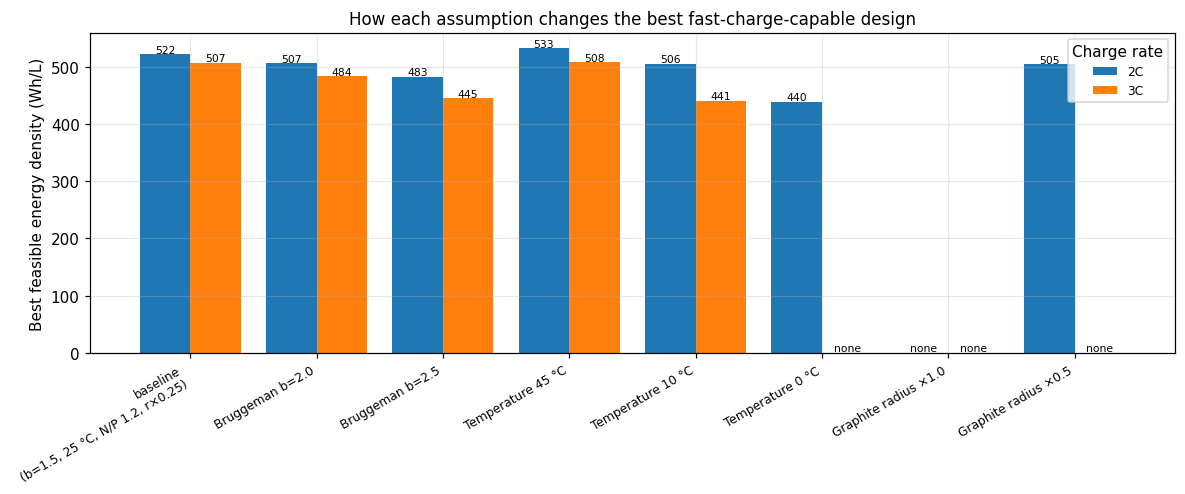

In [36]:
# Overview chart: best feasible energy density at each C-rate across all scenarios
fig, ax = plt.subplots(figsize=(11, 4.6))
names = list(scenarios.keys())
w = 0.8 / len(C_RATES)
for k, c in enumerate(C_RATES):
    vals = summary[summary["C-rate"] == c]["best feasible Wh/L"].values
    bars = ax.bar(np.arange(len(names)) + k * w, np.nan_to_num(vals, nan=0), w, label=f"{c:.0f}C")
    for b_, v in zip(bars, vals):
        ax.text(b_.get_x() + b_.get_width() / 2, (0 if np.isnan(v) else v) + 3, "none" if np.isnan(v) else f"{v:.0f}", ha="center", fontsize=7)
ax.set_xticks(np.arange(len(names)) + w * (len(C_RATES) - 1) / 2)
ax.set_xticklabels([n.replace(" (", "\n(") for n in names], rotation=30, ha="right", fontsize=8)
ax.set(ylabel="Best feasible energy density (Wh/L)", title="How each assumption changes the best fast-charge-capable design")
ax.legend(title="Charge rate")
show("sec10_summary_best_energy")

## 10.1 Export everything
Bundles all CSVs and PNG figures into `lfp_study_outputs.zip`. In Colab the second cell downloads it.

In [37]:
with zipfile.ZipFile("lfp_study_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["results", "figures"]:
        for f in sorted(os.listdir(folder)):
            z.write(os.path.join(folder, f))
print("Created lfp_study_outputs.zip with", len(zipfile.ZipFile("lfp_study_outputs.zip").namelist()), "files")

Created lfp_study_outputs.zip with 34 files


In [38]:
try:
    from google.colab import files
    files.download("lfp_study_outputs.zip")
except ImportError:
    print("Not running in Colab - find lfp_study_outputs.zip in the working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# 11. Interpreting the results (fill in with your own numbers)

1. **Baseline trade-off:** energy density rises with thickness and falls with porosity. The strict feasible window is bounded by the voltage cut-off (transport) and by anode plating.
2. **Tortuosity (Sec. 6):** a larger Bruggeman exponent reduces the feasible thickness at every porosity. Quote: *max feasible thickness at 3C fell from __ µm (b = 1.5) to __ µm (b = 2.5).*
3. **Temperature (Sec. 7):** cold operation shrinks the window and can eliminate it at 3C. Quote the temperature at which the 3C window closes.
4. **Anode (Sec. 8):** compare the effect of graphite particle size with the effect of N/P. If particle size dominates, the anode is the bottleneck.
5. **Charging time (Sec. 9):** compare the strict and CC-CV windows and check which constraint (plating vs voltage limit) binds. Quote the *t80 penalty* for the best designs.

**Limitations to state in a report/interview:** Prada2013 parameters with an assumed faster anode; isothermal model; plating is a thermodynamic screen
(anode potential < 0 V), not a plating-kinetics/reversibility model; energy density ignores tabs/packaging; no degradation modelled.